# VentureScout · Notebook 2 : exploration des données (EDA) et exploration non supervisée

**Rappel du projet.** Prédire si une startup qui vient de faire sa première levée *angel/seed* (date T) lèvera auprès de fonds de capital-risque (tour Series A/B/C ou *venture*) dans les 24 mois. Classification binaire, données tabulaires numériques et catégorielles.

**Données.** Tableau construit dans le notebook 1 à partir de l'export Crunchbase d'octobre 2013 (https://github.com/datahoarder/crunchbase-october-2013) : une ligne par startup, variables figées à la date T.

**Plan.**
1. Métadonnées
2. Valeurs manquantes
3. Distributions, mise à l'échelle et valeurs aberrantes
4. Étude de la variable cible
5. Corrélations, sélection de variables, réduction de dimension, détection d'anomalies
6. Clustering non supervisé
7. Interprétations, hypothèses et conclusions

**Remarque sur la consigne « pas de séries temporelles ».** Le tableau est statique (une ligne par startup) ; la dimension temporelle sert seulement à construire la cible sans fuite d'information. Elle est en revanche utilisée pour le découpage train / test (cohortes anciennes vs récentes), pour mesurer la capacité du modèle à généraliser dans le temps.

In [1]:
# Tous les imports (testé avec : pandas 2.x, numpy 2.x, scikit-learn 1.5+, matplotlib 3.8+, seaborn 0.13)
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
SEED = 42

In [2]:
# Chargement : dossier local s'il existe, sinon GitHub (Colab)
BASE_URL = "https://raw.githubusercontent.com/samiguessoum/hedgehogs-credit-risk-ml/main/venturescout/data/"
chemin = "processed/venturescout_dataset.csv"
local = Path("../data") / chemin
df = pd.read_csv(local if local.exists() else BASE_URL + chemin, parse_dates=["T"])
df.head()

,permalink,name,T,annee_T,categorie,etat,region,age_a_T_mois,date_creation_connue,montant_T_usd,nb_tours_T,nb_investisseurs_T,nb_fonds_T,nb_business_angels_T,nb_entreprises_T,investisseurs_connus_T,exp_max_investisseurs,exp_moy_investisseurs,succes_max_investisseurs,tours_secteur_12m,tours_vc_secteur_12m,tours_etat_12m,y_alt_investisseurs,y
0,/company/1,One Inc.,2011-07-20,2011,mobile,CA,SF Bay,-0.4,1,1000050.0,1,8,4,4,0,1,222.0,70.25,168.0,231,128,1505,0,0
1,/company/1000memories,1000memories,2010-01-01,2010,web,CA,SF Bay,-5.9,1,15000.0,1,2,1,0,1,1,77.0,48.00,16.0,257,144,1204,1,1
2,/company/10bestthings,10BestThings,2009-04-01,2009,web,OH,Cleveland,0.0,1,50000.0,1,0,0,0,0,0,NaN,NaN,NaN,272,169,22,0,0
3,/company/140fire,140Fire,2010-05-05,2010,advertising,CA,Los Angeles,4.1,1,500000.0,1,0,0,0,0,0,NaN,NaN,NaN,203,145,1471,0,0
4,/company/169-st,169 ST.,2009-06-01,2009,games_video,FL,Orlando,0.6,1,50000.0,1,0,0,0,0,0,NaN,NaN,NaN,109,79,36,0,0


## 1. Métadonnées

In [3]:
print(f"{df.shape[0]} startups (instances) x {df.shape[1]} colonnes")
CIBLE = "y"
IDENTIFIANTS = ["permalink", "name", "T"]
CATEGORIELLES = ["categorie", "etat", "region"]
BINAIRES = ["date_creation_connue", "investisseurs_connus_T"]
NUMERIQUES = ["annee_T", "age_a_T_mois", "montant_T_usd", "nb_tours_T", "nb_investisseurs_T", "nb_fonds_T",
              "nb_business_angels_T", "nb_entreprises_T", "exp_max_investisseurs", "exp_moy_investisseurs",
              "succes_max_investisseurs", "tours_secteur_12m", "tours_vc_secteur_12m", "tours_etat_12m"]
print(f"{len(NUMERIQUES)} numériques, {len(CATEGORIELLES)} catégorielles, {len(BINAIRES)} binaires, + cible et identifiants")
df.dtypes.to_frame("type").T

2503 startups (instances) x 24 colonnes
14 numériques, 3 catégorielles, 2 binaires, + cible et identifiants


,permalink,name,T,annee_T,categorie,etat,region,age_a_T_mois,date_creation_connue,montant_T_usd,nb_tours_T,nb_investisseurs_T,nb_fonds_T,nb_business_angels_T,nb_entreprises_T,investisseurs_connus_T,exp_max_investisseurs,exp_moy_investisseurs,succes_max_investisseurs,tours_secteur_12m,tours_vc_secteur_12m,tours_etat_12m,y_alt_investisseurs,y
type,str,str,datetime64[us],int64,str,str,str,float64,int64,float64,int64,int64,int64,int64,int64,int64,float64,float64,float64,int64,int64,int64,int64,int64


In [4]:
df[CATEGORIELLES].describe().T

,count,unique,top,freq
categorie,2482,42,web,517
etat,2454,45,CA,1045
region,2503,223,SF Bay,756


In [5]:
df[NUMERIQUES].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
annee_T,2503.0,2009.2,1.7,2005.0,2008.0,2010.0,2011.0,2011.0
age_a_T_mois,2287.0,9.0,20.4,-66.1,0.0,3.9,12.4,274.9
montant_T_usd,1861.0,421483.4,384861.7,1000.0,100000.0,300000.0,700000.0,1475000.0
nb_tours_T,2503.0,1.0,0.1,1.0,1.0,1.0,1.0,3.0
nb_investisseurs_T,2503.0,1.3,2.2,0.0,0.0,1.0,1.0,26.0
nb_fonds_T,2503.0,0.5,0.9,0.0,0.0,0.0,1.0,9.0
nb_business_angels_T,2503.0,0.6,1.7,0.0,0.0,0.0,0.0,23.0
nb_entreprises_T,2503.0,0.2,0.4,0.0,0.0,0.0,0.0,4.0
exp_max_investisseurs,1436.0,22.8,39.9,0.0,0.0,4.0,26.0,240.0
exp_moy_investisseurs,1436.0,14.7,27.2,0.0,0.0,3.0,15.0,234.0


**Commentaires.**
- **2 503 instances et 19 variables explicatives** (14 numériques, 3 catégorielles, 2 binaires) : c'est un jeu « petit » au regard de la consigne (10 k–100 k), conséquence du filtrage nécessaire pour définir proprement la cible (1re levée angel entre 2005 et 2011, 24 mois d'observation). Avec ~2 500 lignes, il faudra privilégier la **validation croisée** et des modèles **régularisés**, et surveiller le sur-apprentissage avec les courbes d'apprentissage.
- `y_alt_investisseurs` est une **définition alternative de la cible** : elle n'est **pas** une variable explicative (fuite d'information) et sera retirée avant la modélisation.
- Toutes les startups sont américaines (l'export 2013 ne contient que les États-Unis) : `etat` et `region` jouent le rôle de la localisation.
- Les variables de comptage (`nb_*`, `exp_*`, `succes_*`) ont une moyenne bien supérieure à la médiane : **distributions très asymétriques** (voir partie 3).

## 2. Valeurs manquantes

,nb_manquants,pourcentage
succes_max_investisseurs,1067,42.6
exp_moy_investisseurs,1067,42.6
exp_max_investisseurs,1067,42.6
montant_T_usd,642,25.6
age_a_T_mois,216,8.6
etat,49,2.0
categorie,21,0.8


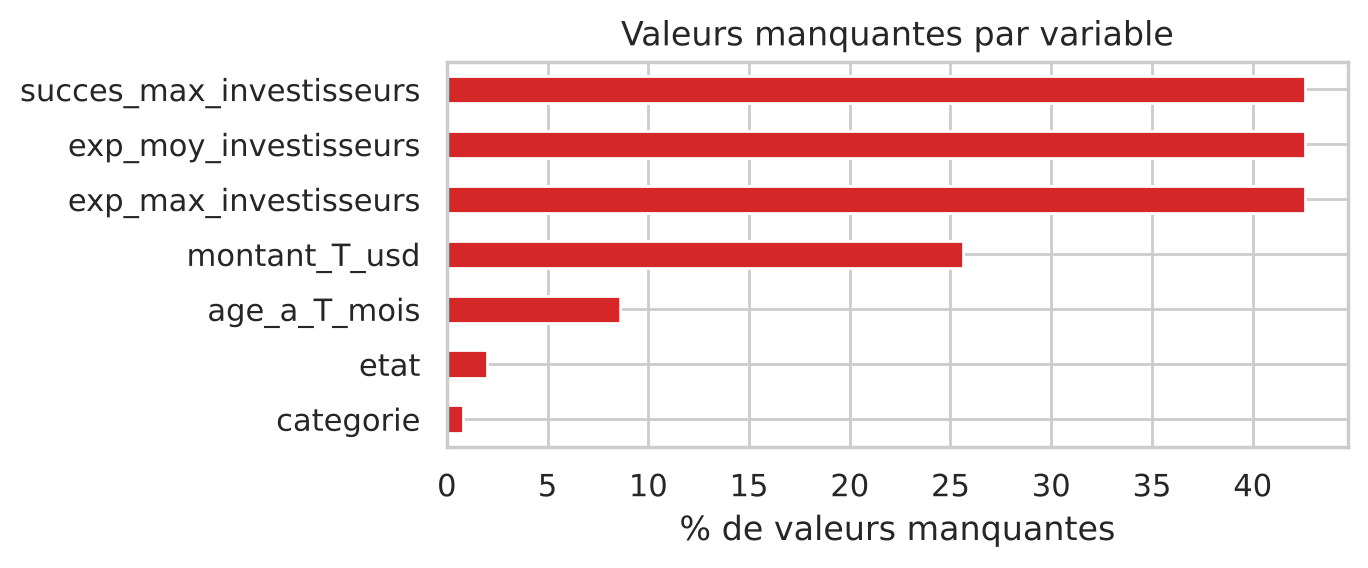

In [6]:
manquants = df.isna().sum()
manquants = manquants[manquants > 0].sort_values(ascending=False)
table = pd.DataFrame({"nb_manquants": manquants, "pourcentage": (100 * manquants / len(df)).round(1)})
display(table)

fig, ax = plt.subplots(figsize=(7, 3))
table["pourcentage"].plot.barh(ax=ax, color="tab:red")
ax.set_xlabel("% de valeurs manquantes"); ax.invert_yaxis(); ax.set_title("Valeurs manquantes par variable")
plt.tight_layout(); plt.show()

In [7]:
# Les valeurs manquantes sont-elles liées à la cible ? (taux de y = 1 selon que la valeur est connue ou non)
lignes = []
for col in table.index:
    m = df[col].isna()
    lignes.append({"variable": col, "taux_y_si_manquant": df.loc[m, CIBLE].mean(), "taux_y_si_connu": df.loc[~m, CIBLE].mean()})
pd.DataFrame(lignes).set_index("variable").round(3)

,taux_y_si_manquant,taux_y_si_connu
variable,,
succes_max_investisseurs,0.144,0.333
exp_moy_investisseurs,0.144,0.333
exp_max_investisseurs,0.144,0.333
montant_T_usd,0.243,0.256
age_a_T_mois,0.231,0.254
etat,0.245,0.253
categorie,0.190,0.253


In [8]:
# Les 3 variables « investisseurs » sont manquantes exactement quand les investisseurs du tour T sont inconnus
print("Manquants exp_max_investisseurs == investisseurs inconnus :",
      (df["exp_max_investisseurs"].isna() == (df["investisseurs_connus_T"] == 0)).all())

Manquants exp_max_investisseurs == investisseurs inconnus : True


**Interprétation et stratégie.**

| Variable | Pourquoi elle manque | Stratégies possibles | Choix retenu |
|---|---|---|---|
| `exp_max/moy_investisseurs`, `succes_max_investisseurs` (43 %) | **Structurel** : la liste des investisseurs du tour T n'est pas renseignée dans Crunchbase. Ce n'est pas aléatoire (lié à la cible, voir tableau). | supprimer les lignes (perte de 43 % des données) ; supprimer les colonnes (perte d'information utile) ; imputer | **Imputer par 0** + garder l'indicateur `investisseurs_connus_T`, qui porte l'information « on ne sait pas » |
| `montant_T_usd` (26 %) | Montant non publié par la startup. | supprimer ; imputer moyenne / médiane ; imputer par modèle (KNN) | **Médiane** (robuste à l'asymétrie) + indicateur `montant_connu` |
| `age_a_T_mois` (9 %) | Date de création non renseignée. | idem | **Médiane** (l'indicateur `date_creation_connue` existe déjà) |
| `etat` (2 %), `categorie` (1 %) | Fiche incomplète. | supprimer ; modalité dédiée | **Modalité `inconnu`** |

Les imputations seront faites **dans les pipelines scikit-learn, ajustées sur le jeu d'entraînement uniquement**, pour ne pas utiliser d'information du jeu de test.

## 3. Distributions, mise à l'échelle et valeurs aberrantes

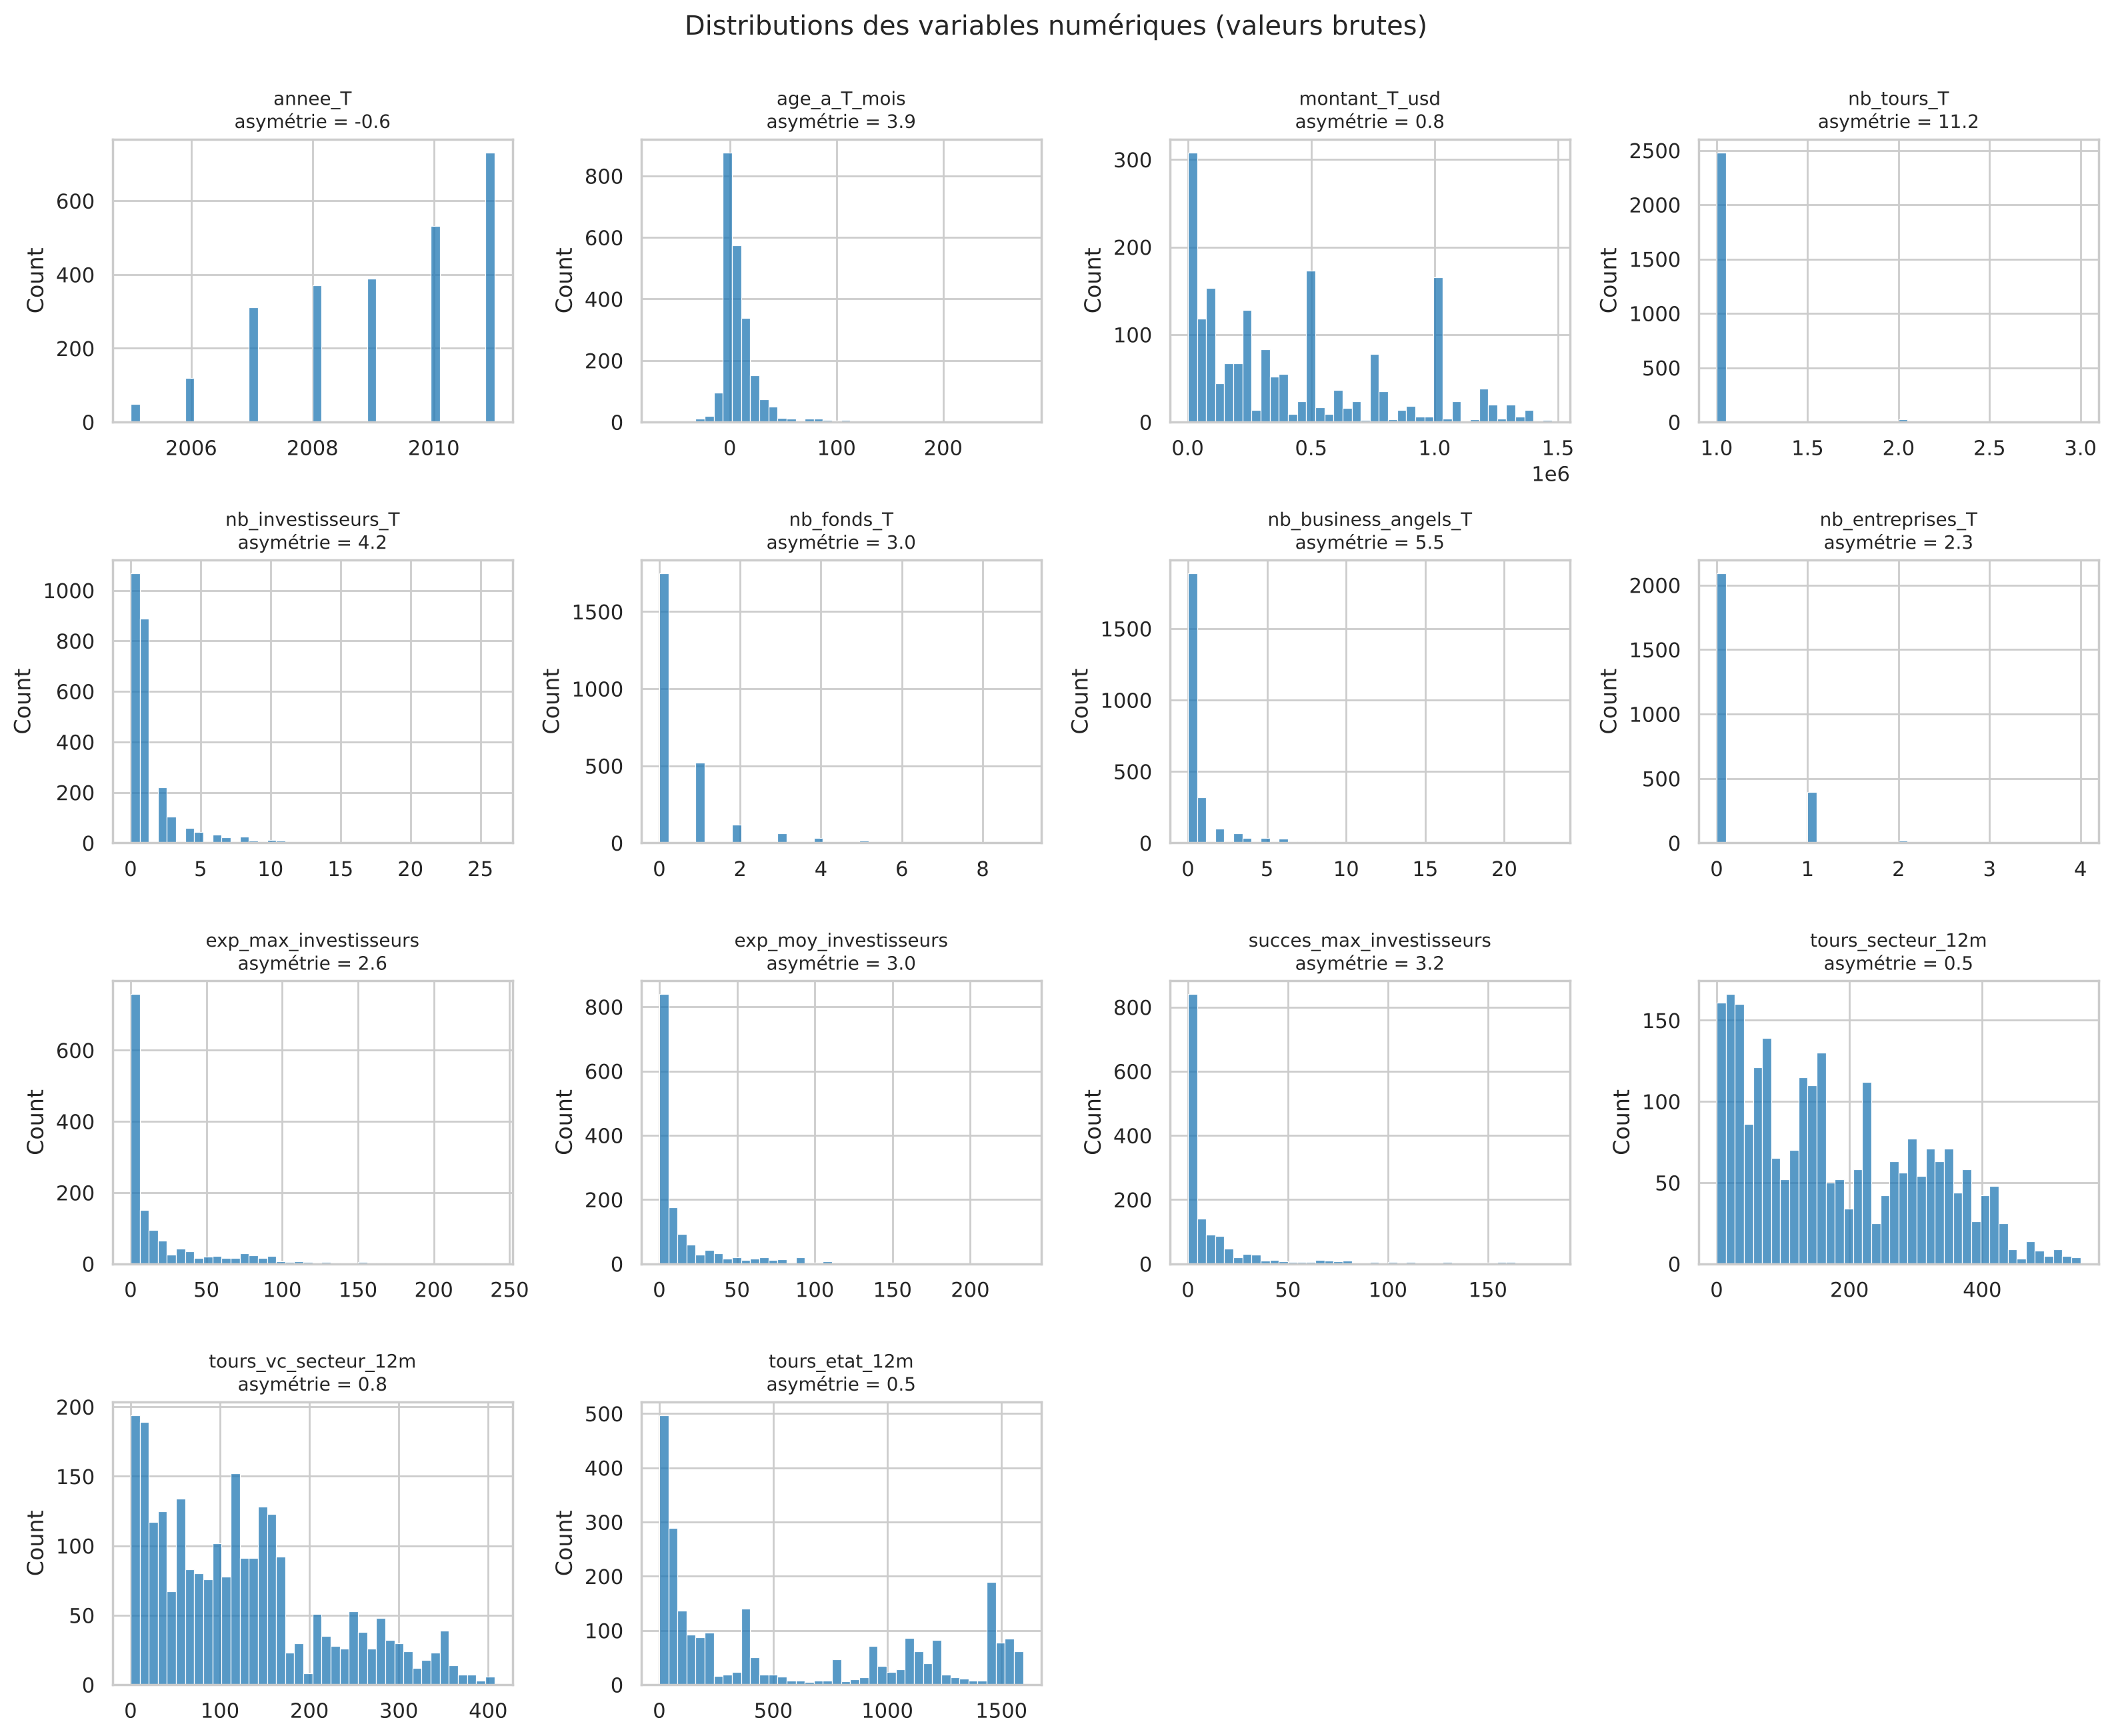

In [9]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, col in zip(axes.ravel(), NUMERIQUES):
    sns.histplot(df[col].dropna(), bins=40, ax=ax, color="tab:blue")
    ax.set_title(f"{col}\nasymétrie = {df[col].skew():.1f}", fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[len(NUMERIQUES):]:
    ax.axis("off")
plt.suptitle("Distributions des variables numériques (valeurs brutes)", y=1.0); plt.tight_layout(); plt.show()

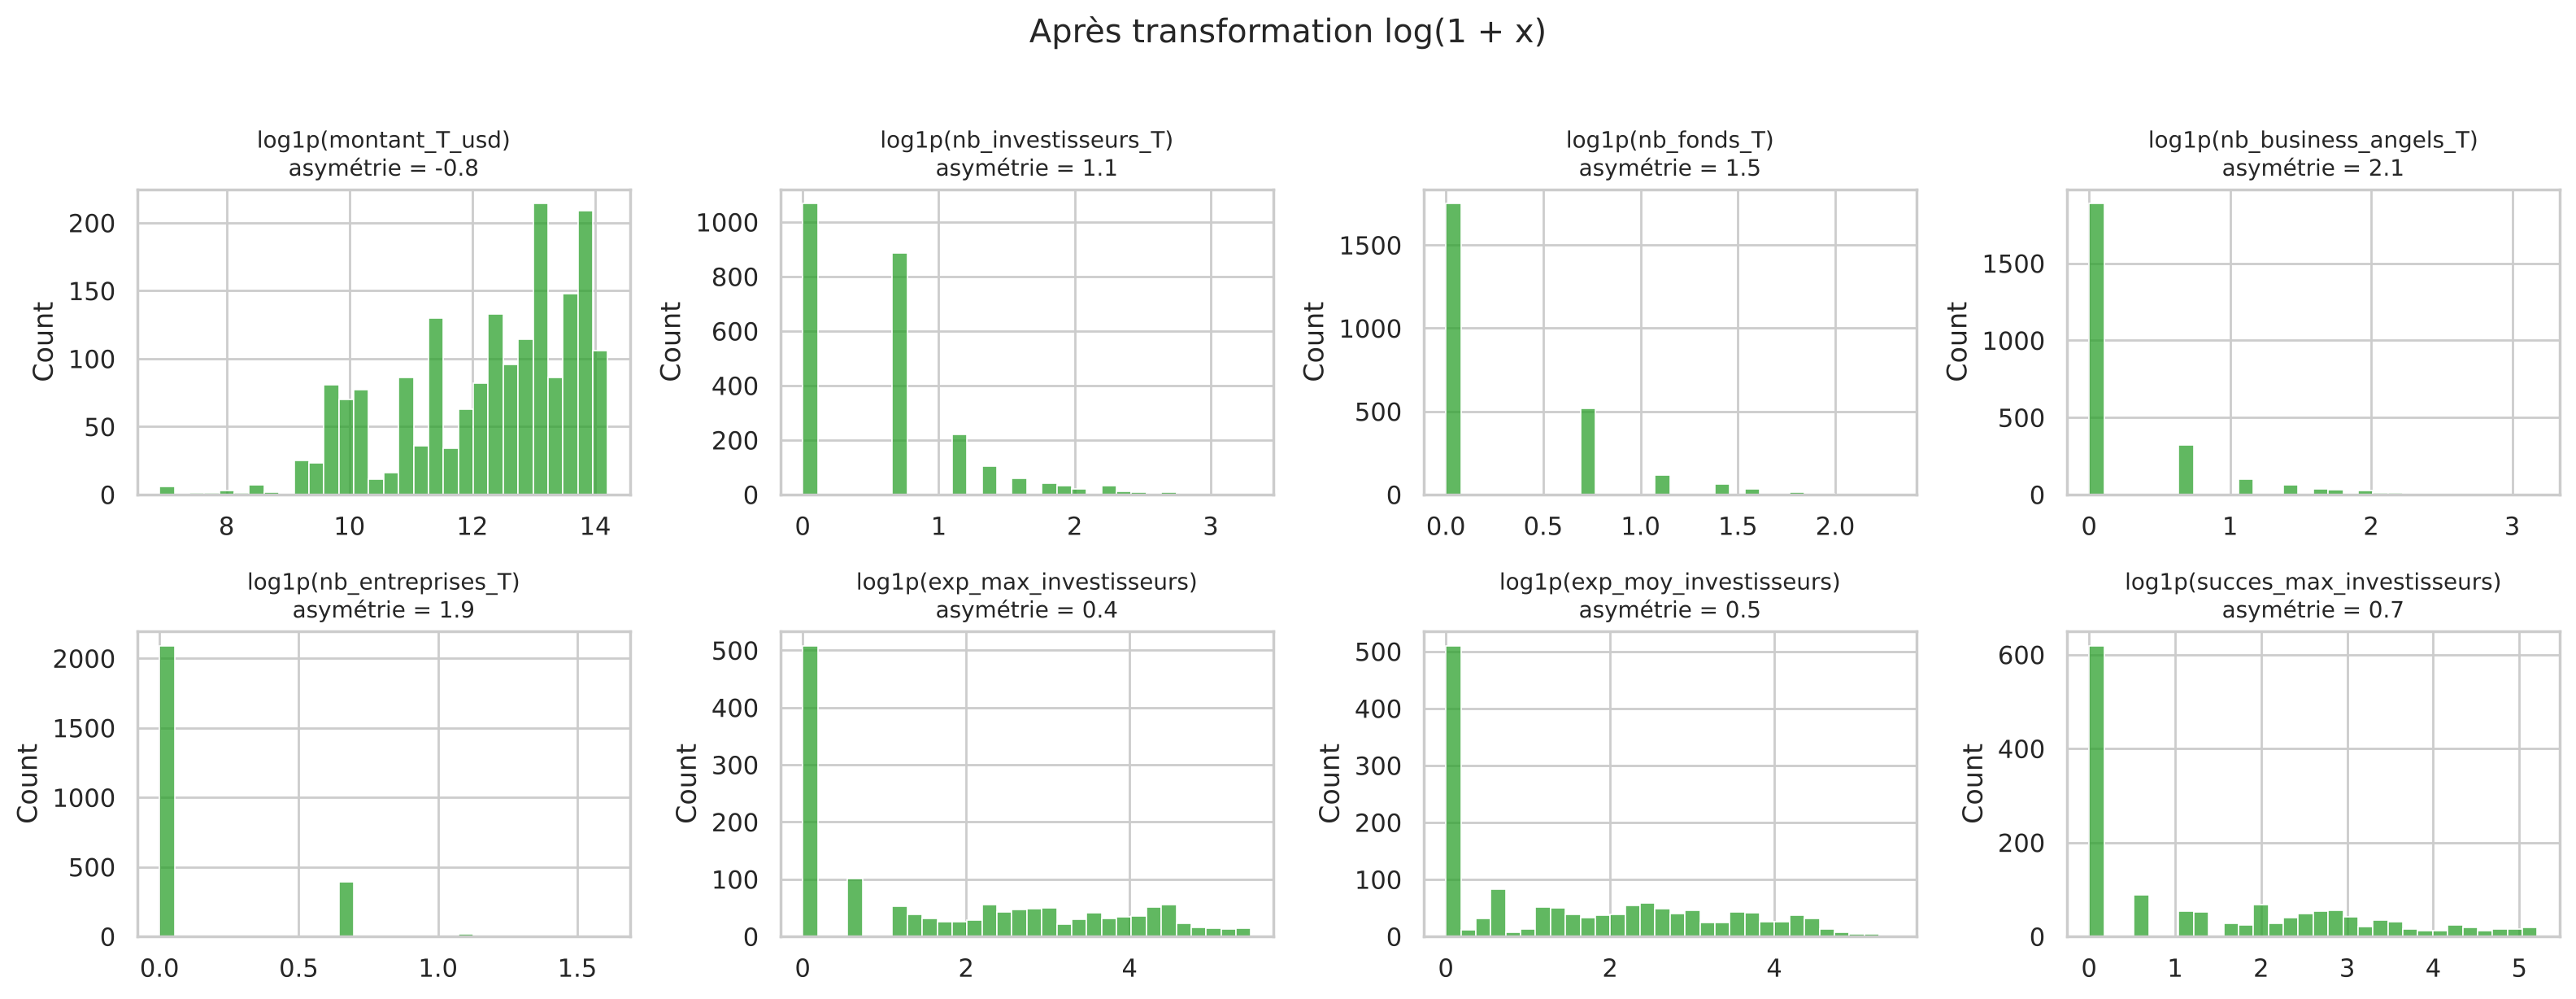

In [10]:
# Transformation log(1 + x) des variables de comptage et de montant, très asymétriques
A_LOGUER = ["montant_T_usd", "nb_investisseurs_T", "nb_fonds_T", "nb_business_angels_T", "nb_entreprises_T",
            "exp_max_investisseurs", "exp_moy_investisseurs", "succes_max_investisseurs"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), A_LOGUER):
    v = np.log1p(df[col].dropna())
    sns.histplot(v, bins=30, ax=ax, color="tab:green")
    ax.set_title(f"log1p({col})\nasymétrie = {v.skew():.1f}", fontsize=10); ax.set_xlabel("")
plt.suptitle("Après transformation log(1 + x)", y=1.02); plt.tight_layout(); plt.show()

In [11]:
# Valeurs aberrantes : règle de l'écart interquartile (IQR)
def nb_aberrantes(s):
    s = s.dropna(); q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

aberr = pd.DataFrame({"brut": {c: nb_aberrantes(df[c]) for c in NUMERIQUES},
                      "après log1p": {c: nb_aberrantes(np.log1p(df[c])) if c in A_LOGUER else np.nan for c in NUMERIQUES}})
aberr["% brut"] = (100 * aberr["brut"] / len(df)).round(1)
aberr

,brut,après log1p,% brut
annee_T,0,NaN,0.0
age_a_T_mois,204,NaN,8.2
montant_T_usd,0,19.0,0.0
nb_tours_T,23,NaN,0.9
nb_investisseurs_T,328,167.0,13.1
nb_fonds_T,117,22.0,4.7
nb_business_angels_T,617,617.0,24.7
nb_entreprises_T,412,412.0,16.5
exp_max_investisseurs,189,0.0,7.6
exp_moy_investisseurs,193,0.0,7.7


Âges négatifs : 357 startups (14.3 %)
count    357.0
mean      -7.9
std       10.7
min      -66.1
25%      -10.0
50%       -4.3
75%       -1.3
max       -0.1
Name: age_a_T_mois, dtype: float64


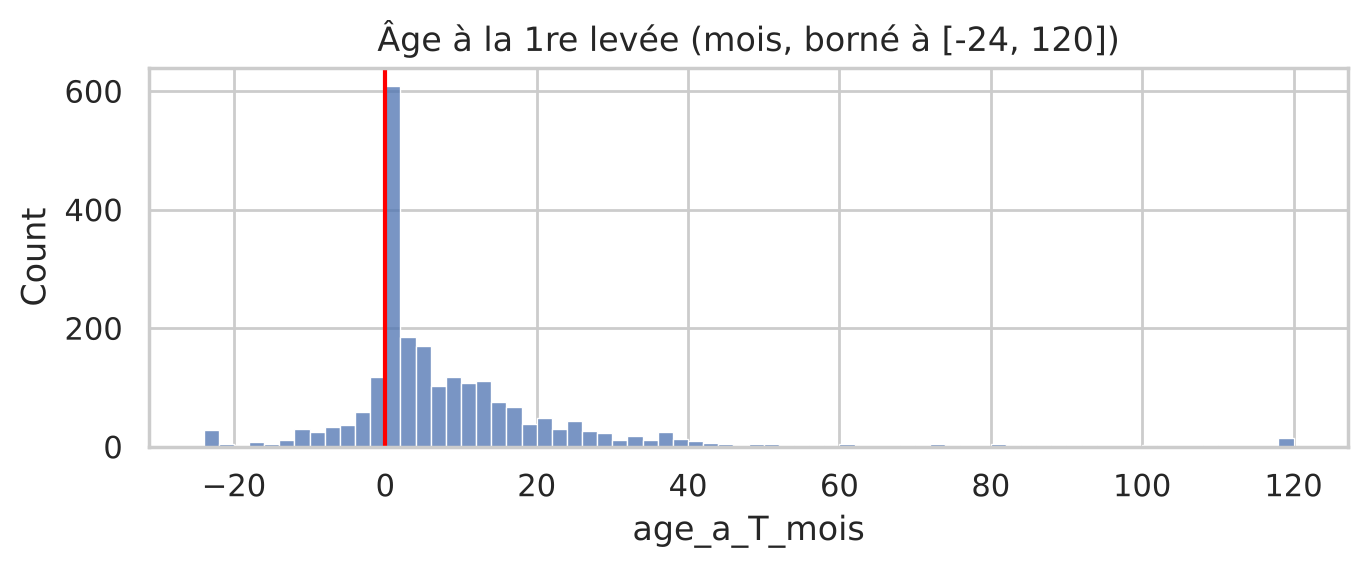

In [12]:
# Anomalie de cohérence : âge négatif = date de création postérieure à la 1re levée
neg = df["age_a_T_mois"] < 0
print(f"Âges négatifs : {neg.sum()} startups ({100 * neg.mean():.1f} %)")
print(df.loc[neg, "age_a_T_mois"].describe().round(1))
fig, ax = plt.subplots(figsize=(7, 3))
sns.histplot(df["age_a_T_mois"].clip(-24, 120), bins=72, ax=ax)
ax.axvline(0, color="red"); ax.set_title("Âge à la 1re levée (mois, borné à [-24, 120])")
plt.tight_layout(); plt.show()

**Interprétation et stratégie.**
- **Asymétrie forte** des comptages et des montants (beaucoup de petites valeurs, quelques très grandes) : la transformation **log(1 + x)** réduit nettement l'asymétrie et le nombre de valeurs aberrantes. Elle sera appliquée dans les pipelines.
- **Mise à l'échelle** : les variables ont des unités très différentes (dollars, nombres de tours, mois). On utilisera un **`StandardScaler`** pour les modèles sensibles à l'échelle (régression logistique régularisée, SVM, KNN, k-means) ; les modèles à base d'arbres n'en ont pas besoin.
- **Valeurs aberrantes** : ce ne sont pas des erreurs (un investisseur très actif comme un grand fonds a réellement financé des centaines de startups). On les **garde**, la transformation log suffit à limiter leur influence.
- **Âges négatifs** : la date de création est souvent arrondie (1er janvier de l'année) ou saisie après coup, d'où des petits écarts négatifs. Stratégie : **ramener les âges négatifs à 0** (la startup venait d'être créée) plutôt que de supprimer ces lignes.
- `montant_T_usd` est plafonné vers 1,5 M$ : c'est la définition d'un tour angel dans Crunchbase, pas une anomalie.

categorie :  42 modalités |  19 modalités avec moins de 20 startups
etat      :  45 modalités |  26 modalités avec moins de 20 startups
region    : 223 modalités | 206 modalités avec moins de 20 startups


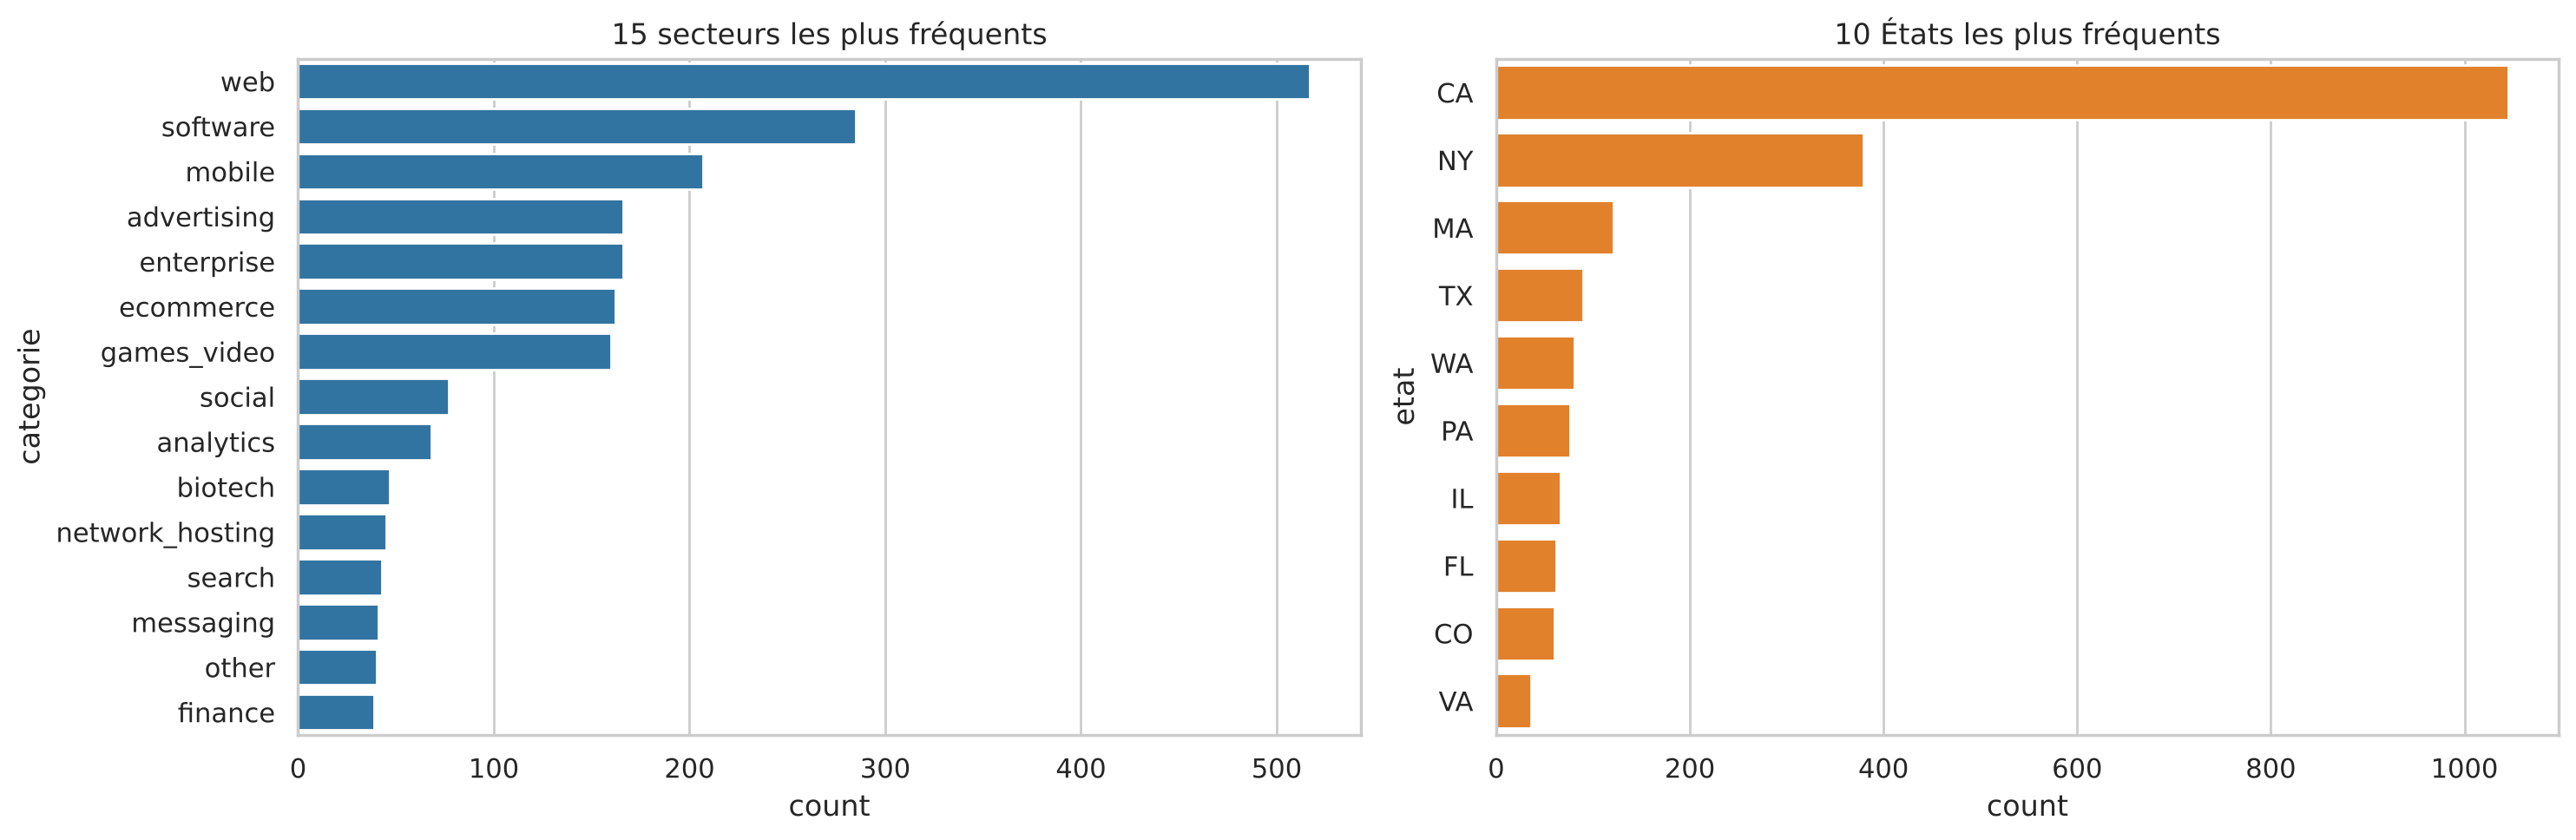

In [13]:
# Variables catégorielles : nombre de modalités et modalités rares
for col in CATEGORIELLES:
    vc = df[col].value_counts()
    print(f"{col:10s}: {vc.size:3d} modalités | {int((vc < 20).sum()):3d} modalités avec moins de 20 startups")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top = df["categorie"].value_counts().head(15).index
sns.countplot(y="categorie", data=df[df["categorie"].isin(top)], order=top, ax=axes[0], color="tab:blue")
axes[0].set_title("15 secteurs les plus fréquents")
top_e = df["etat"].value_counts().head(10).index
sns.countplot(y="etat", data=df[df["etat"].isin(top_e)], order=top_e, ax=axes[1], color="tab:orange")
axes[1].set_title("10 États les plus fréquents")
plt.tight_layout(); plt.show()

**Stratégie pour les catégorielles.** `region` (plus de 200 modalités) est redondante avec `etat` et trop fragmentée : on la **retire**. Pour `categorie` et `etat`, on **regroupe les modalités rares** (moins de 20 startups) dans une modalité `autre`, puis encodage **one-hot**. Cela évite de créer des dizaines de colonnes presque vides.

## 4. Étude de la variable cible

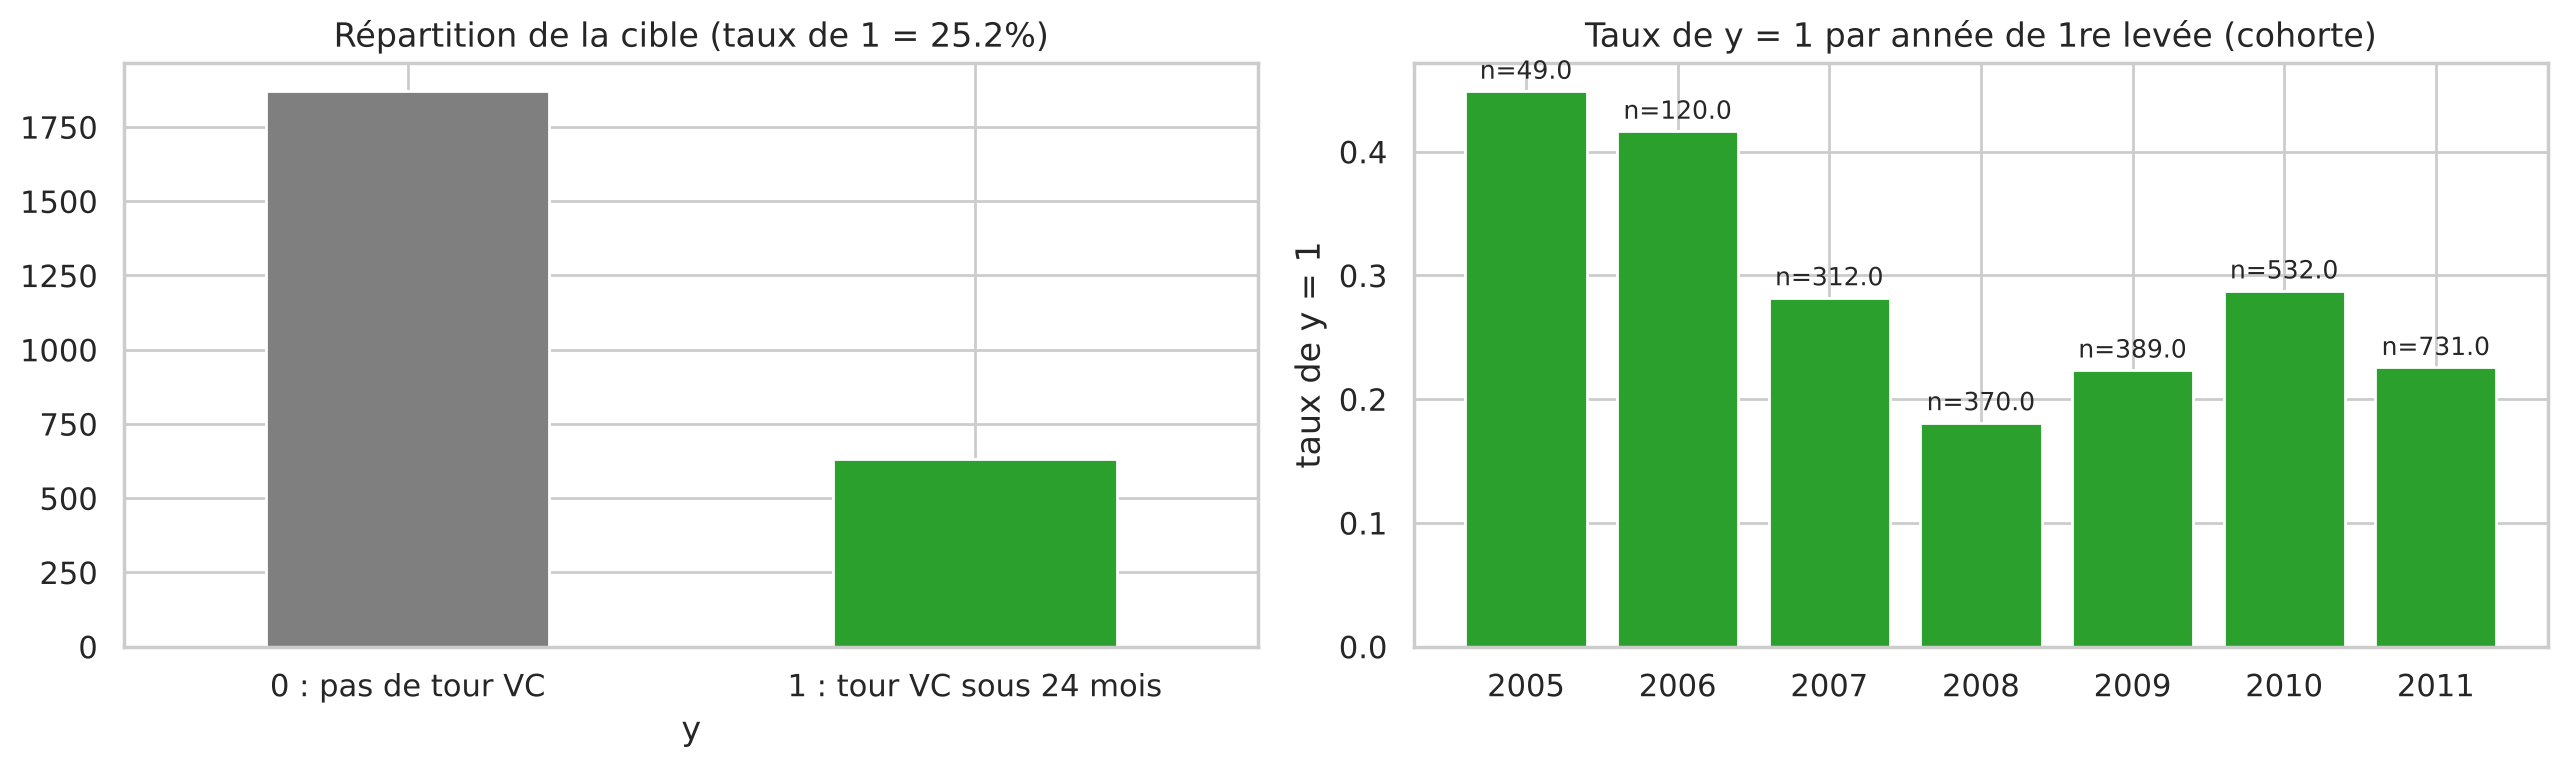

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df[CIBLE].value_counts().sort_index().plot.bar(ax=axes[0], color=["tab:gray", "tab:green"])
axes[0].set_xticklabels(["0 : pas de tour VC", "1 : tour VC sous 24 mois"], rotation=0)
axes[0].set_title(f"Répartition de la cible (taux de 1 = {df[CIBLE].mean():.1%})")
par_an = df.groupby("annee_T")[CIBLE].agg(["mean", "size"])
axes[1].bar(par_an.index, par_an["mean"], color="tab:green")
for x, (m, n) in par_an.iterrows():
    axes[1].text(x, m + 0.01, f"n={n}", ha="center", fontsize=9)
axes[1].set_title("Taux de y = 1 par année de 1re levée (cohorte)"); axes[1].set_ylabel("taux de y = 1")
plt.tight_layout(); plt.show()

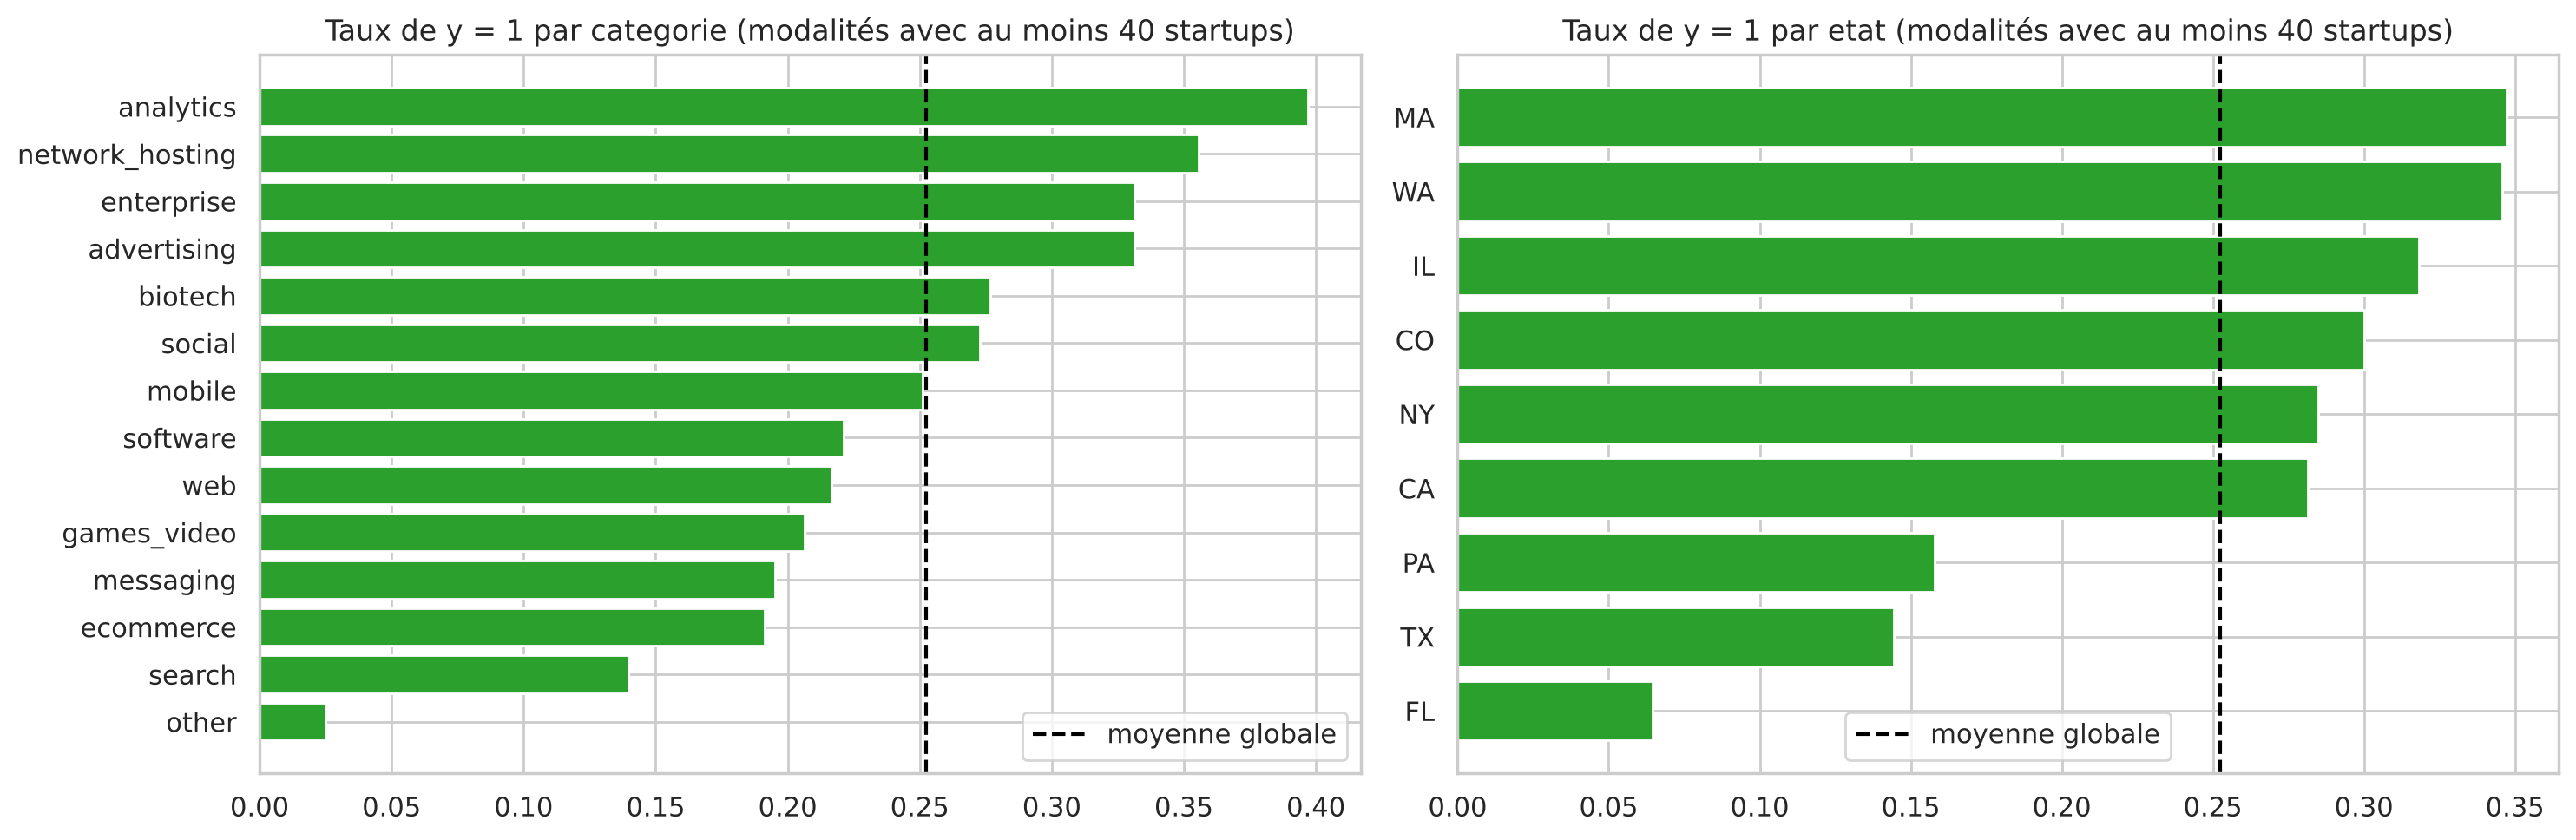

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col in zip(axes, ["categorie", "etat"]):
    t = df.groupby(col)[CIBLE].agg(["mean", "size"]).query("size >= 40").sort_values("mean")
    ax.barh(t.index, t["mean"], color="tab:green")
    ax.axvline(df[CIBLE].mean(), color="black", ls="--", label="moyenne globale")
    ax.set_title(f"Taux de y = 1 par {col} (modalités avec au moins 40 startups)"); ax.legend()
plt.tight_layout(); plt.show()

**Interprétation et décisions.**
- **Classes déséquilibrées** : environ 1 startup sur 4 obtient un tour VC dans les 24 mois. Ce n'est pas extrême, mais un modèle « bête » qui répond toujours 0 aurait déjà 75 % d'exactitude. Décisions :
  - mesurer les modèles avec des métriques adaptées : **ROC-AUC, PR-AUC, F1**, plutôt que l'exactitude seule ;
  - découpages **stratifiés** (même proportion de 1 dans chaque morceau) ;
  - tester `class_weight="balanced"` et un **sur-échantillonnage (SMOTE) appliqué au jeu d'entraînement seulement**, après le découpage.
- **Effet cohorte** : le taux de succès varie selon l'année (plus élevé en 2005–2006, plus bas en 2008, année de crise financière). Le contexte économique compte. Comme on veut un outil utilisable sur de nouvelles startups, le **jeu de test sera la cohorte la plus récente (2011)**, et l'entraînement / la validation croisée se feront sur 2005–2010.
- **Secteur et État** : des écarts nets apparaissent. Côté secteurs, `analytics`, `network_hosting`, `enterprise` et `advertising` dépassent 33 %, alors que `search` et `ecommerce` sont sous 20 %. Côté États, le Massachusetts et l'État de Washington sont autour de 35 %, la Floride et le Texas sous 15 %. Ces variables sont probablement utiles.

## 5. Corrélations, sélection de variables, réduction de dimension et anomalies

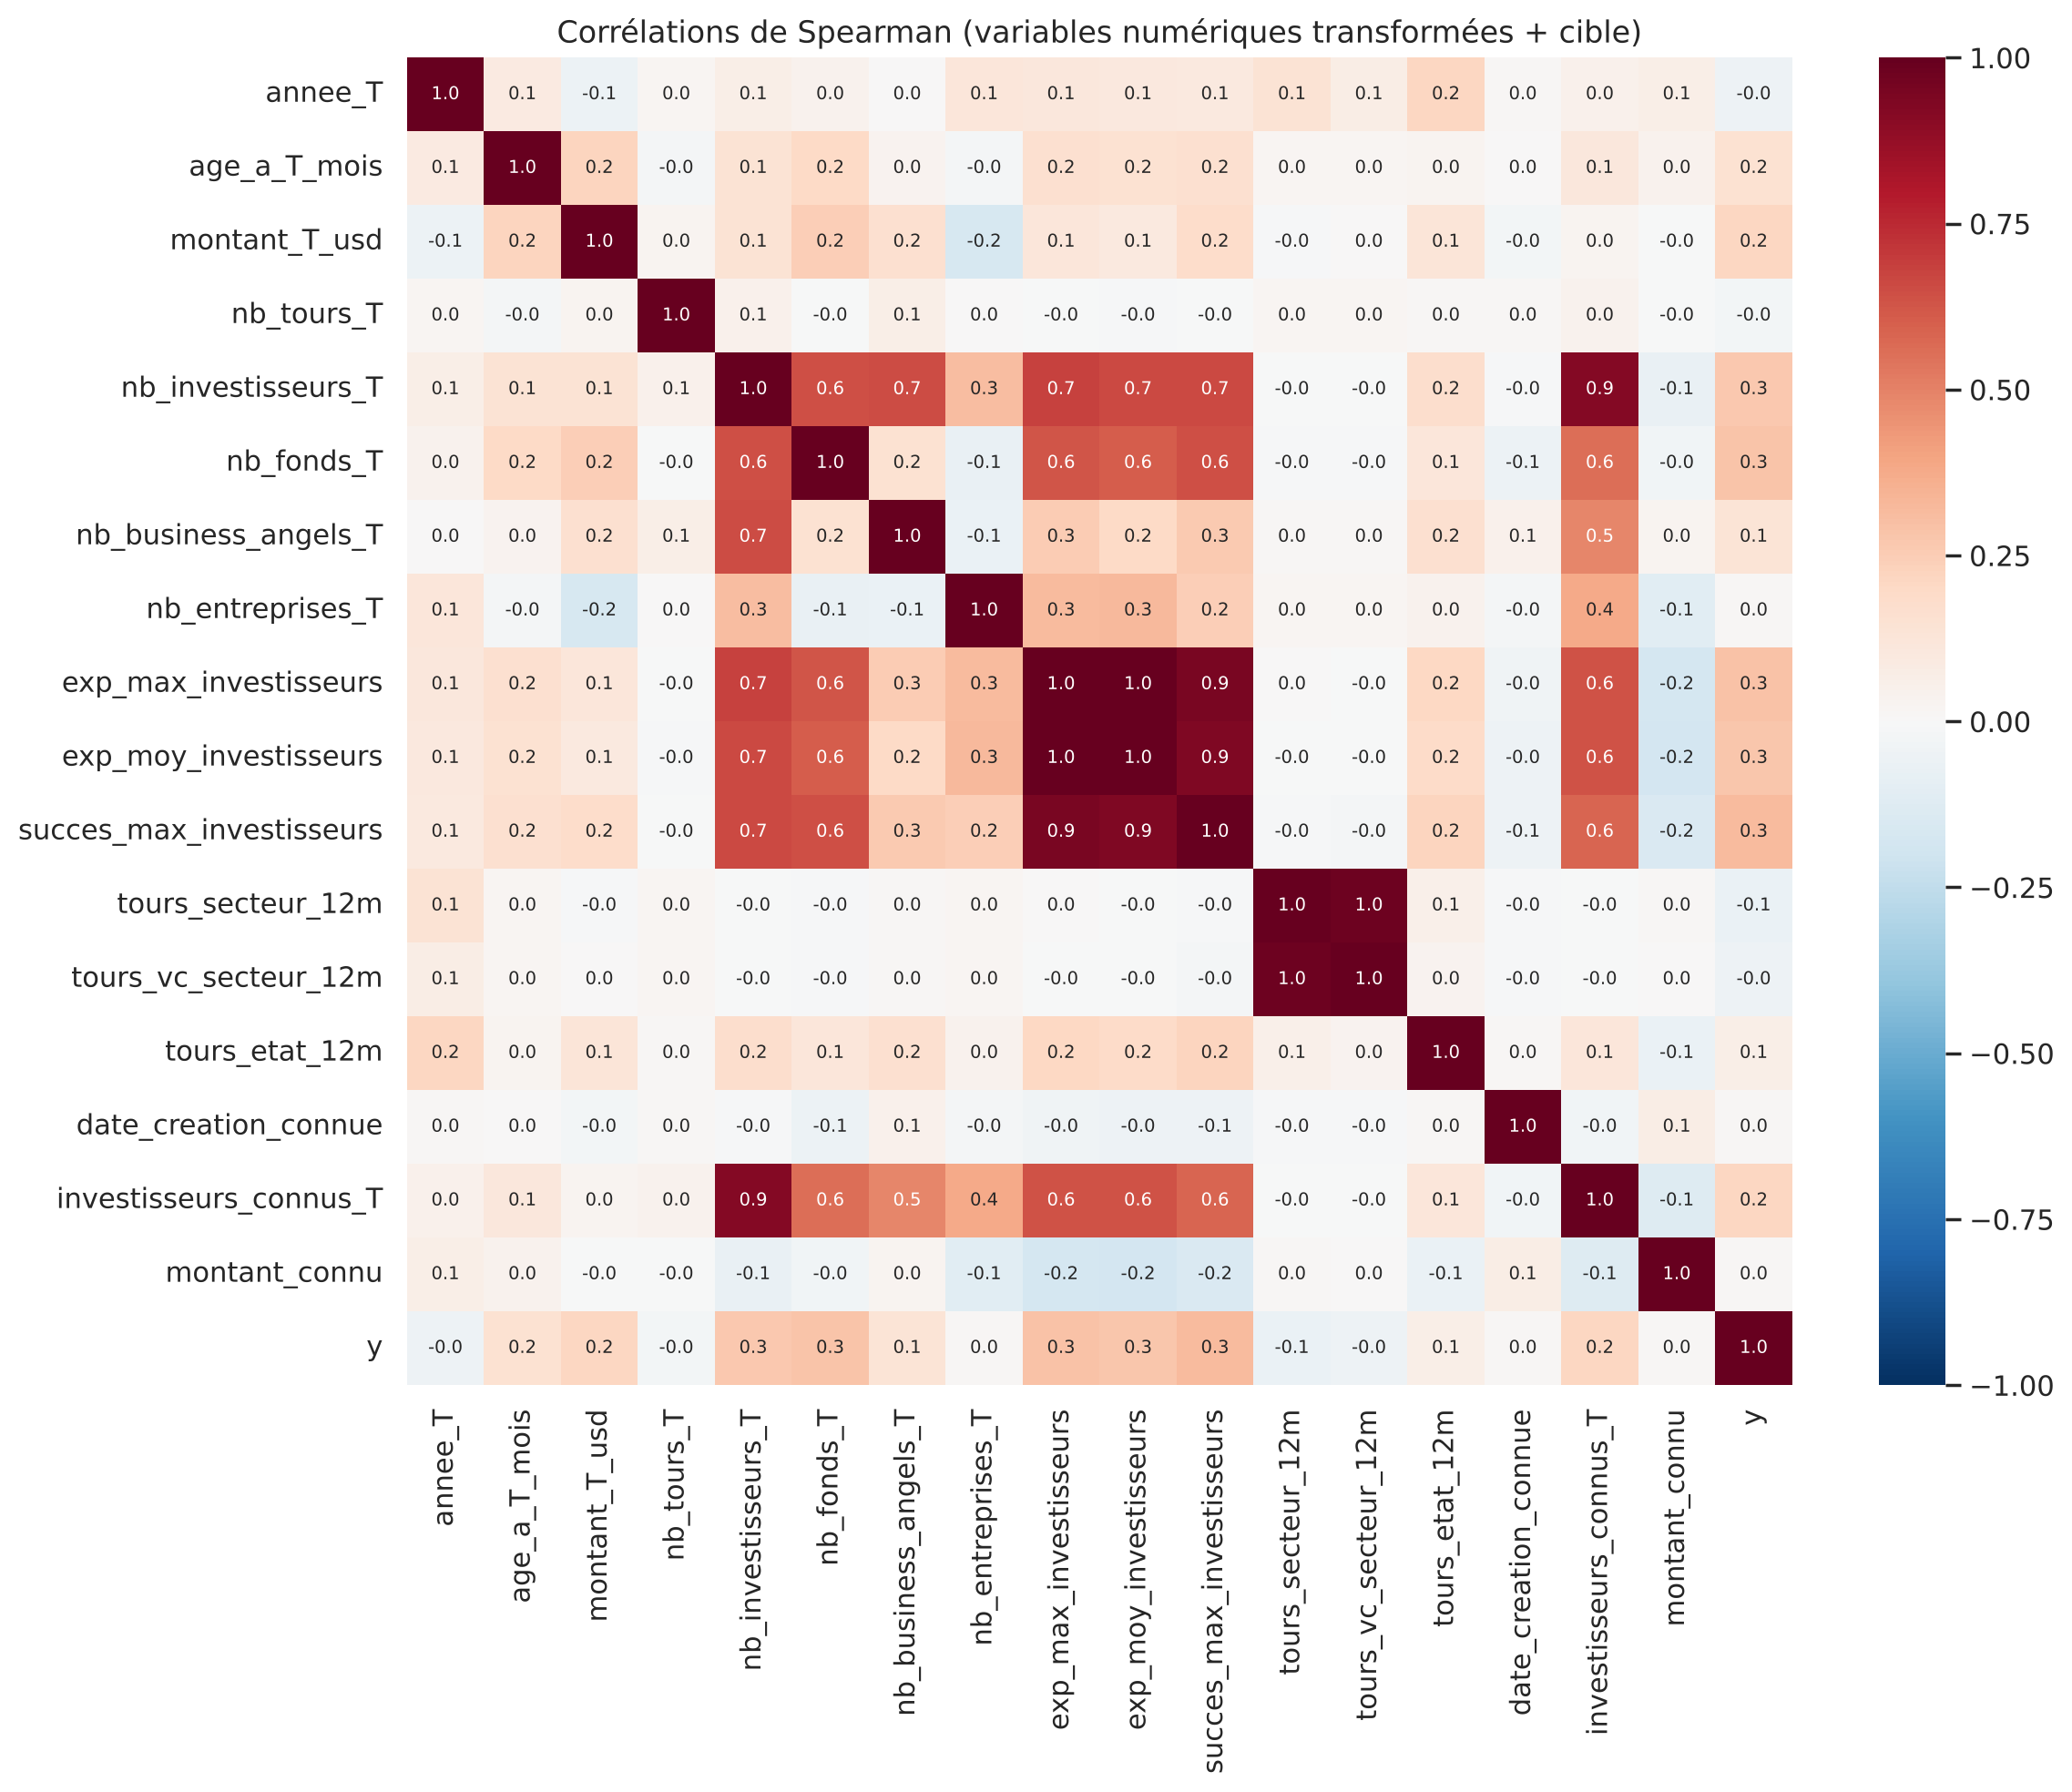

In [16]:
# Préparation d'une version numérique « propre » pour l'analyse (mêmes choix que ceux décidés plus haut)
X = df[NUMERIQUES + BINAIRES].copy()
X["age_a_T_mois"] = X["age_a_T_mois"].clip(lower=0)
for c in ["exp_max_investisseurs", "exp_moy_investisseurs", "succes_max_investisseurs"]:
    X[c] = X[c].fillna(0)
X["montant_connu"] = X["montant_T_usd"].notna().astype(int)
X = X.fillna(X.median())
X_brut = X.copy()   # version imputée mais non transformée, pour lire les profils de clusters en unités réelles
for c in A_LOGUER:
    X[c] = np.log1p(X[c])

corr = X.assign(y=df[CIBLE]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Corrélations de Spearman (variables numériques transformées + cible)")
plt.tight_layout(); plt.show()

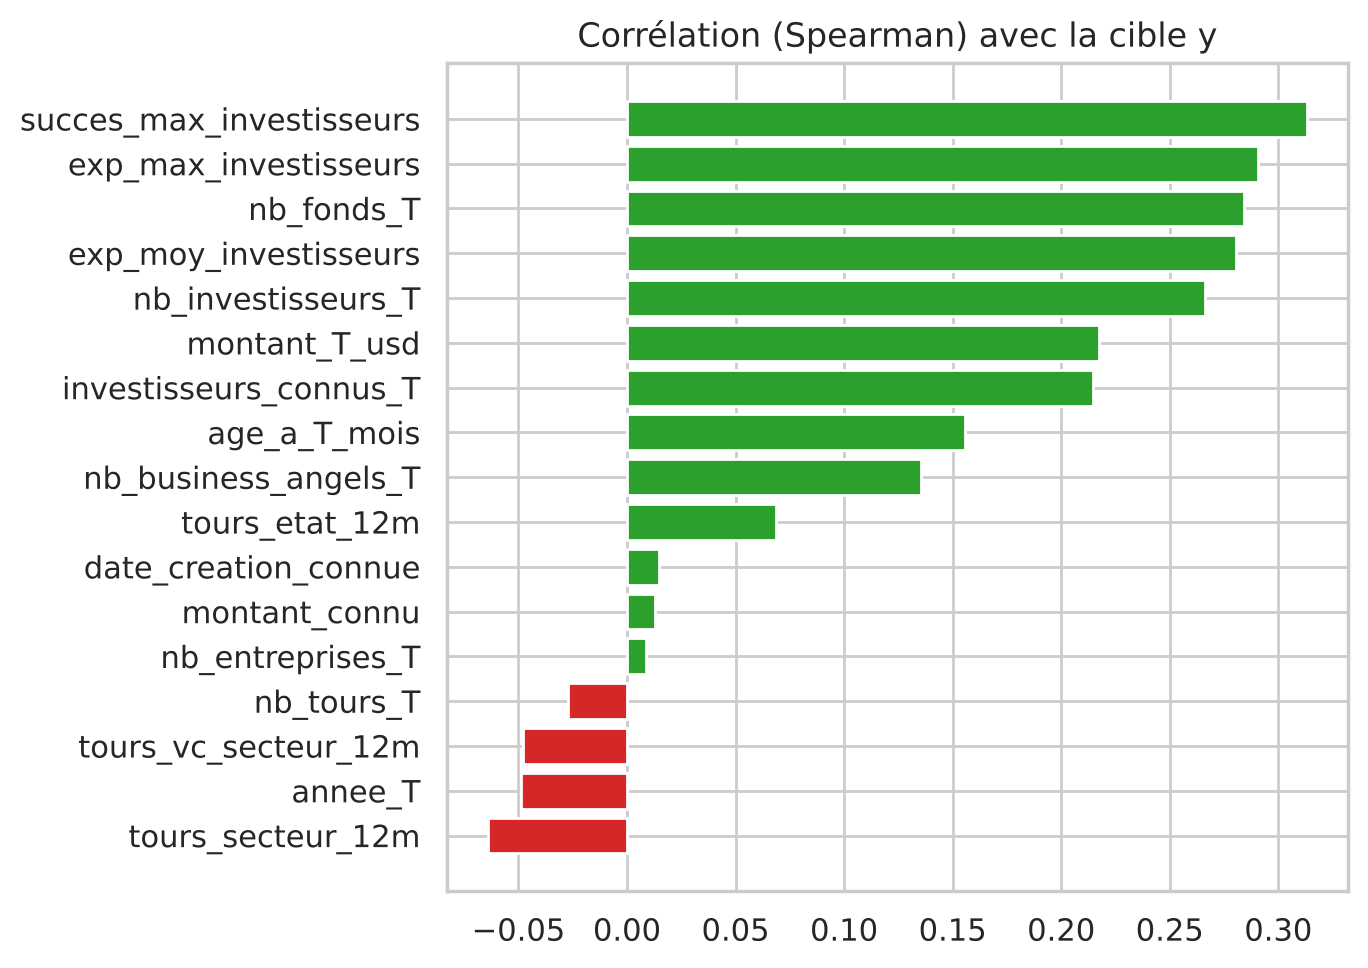

,variable 1,variable 2,corrélation
0,nb_investisseurs_T,investisseurs_connus_T,0.91
1,exp_max_investisseurs,exp_moy_investisseurs,1.00
2,exp_max_investisseurs,succes_max_investisseurs,0.95
3,exp_moy_investisseurs,succes_max_investisseurs,0.94
4,tours_secteur_12m,tours_vc_secteur_12m,0.98


In [17]:
# Corrélation de chaque variable avec la cible
cy = corr[CIBLE].drop(CIBLE).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(cy.index, cy.values, color=np.where(cy.values > 0, "tab:green", "tab:red"))
ax.set_title("Corrélation (Spearman) avec la cible y"); plt.tight_layout(); plt.show()

# Paires de variables très corrélées (|r| > 0.8) : redondance
paires = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]
          if abs(corr.loc[a, b]) > 0.8 and CIBLE not in (a, b)]
pd.DataFrame(paires, columns=["variable 1", "variable 2", "corrélation"])

In [18]:
# Lien entre variables catégorielles et cible : V de Cramér (0 = aucun lien, 1 = lien parfait)
def v_cramer(a, b):
    t = pd.crosstab(a, b); chi2 = chi2_contingency(t)[0]; n = t.values.sum()
    return np.sqrt(chi2 / (n * (min(t.shape) - 1)))

pd.Series({c: v_cramer(df[c].fillna("inconnu"), df[CIBLE]) for c in CATEGORIELLES}, name="V de Cramér avec y").round(3)

categorie    0.208
etat         0.185
region       0.315
Name: V de Cramér avec y, dtype: float64

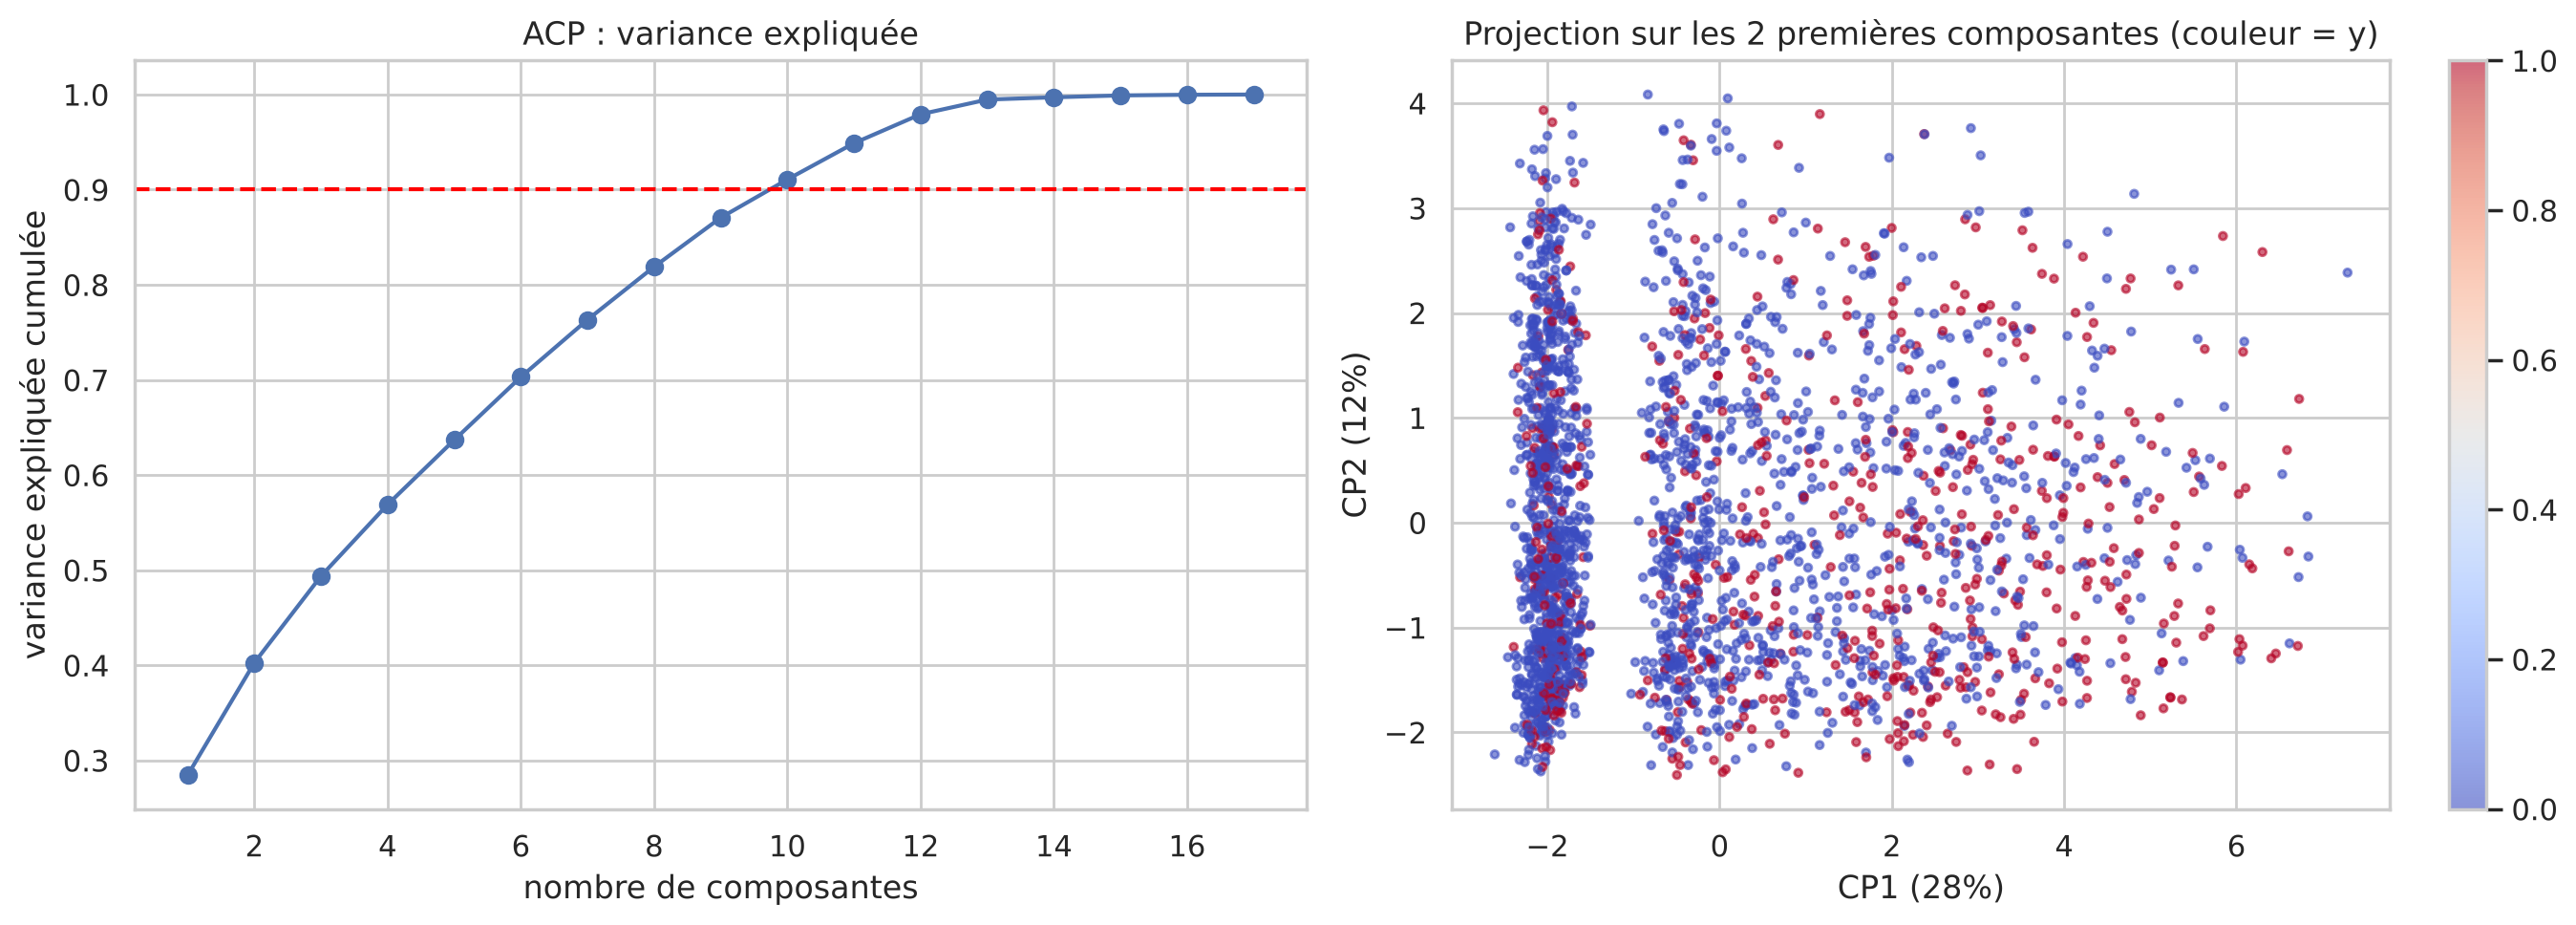

Composantes nécessaires pour 90 % de la variance : 10 sur 17


In [19]:
# Réduction de dimension : ACP (analyse en composantes principales)
X_std = StandardScaler().fit_transform(X)
acp = PCA(random_state=SEED).fit(X_std)
var_cum = np.cumsum(acp.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, len(var_cum) + 1), var_cum, marker="o")
axes[0].axhline(0.9, color="red", ls="--"); axes[0].set_xlabel("nombre de composantes")
axes[0].set_ylabel("variance expliquée cumulée"); axes[0].set_title("ACP : variance expliquée")
proj = acp.transform(X_std)[:, :2]
sc = axes[1].scatter(proj[:, 0], proj[:, 1], c=df[CIBLE], cmap="coolwarm", s=8, alpha=0.6)
axes[1].set_xlabel(f"CP1 ({acp.explained_variance_ratio_[0]:.0%})"); axes[1].set_ylabel(f"CP2 ({acp.explained_variance_ratio_[1]:.0%})")
axes[1].set_title("Projection sur les 2 premières composantes (couleur = y)"); plt.colorbar(sc, ax=axes[1])
plt.tight_layout(); plt.show()
print("Composantes nécessaires pour 90 % de la variance :", int(np.argmax(var_cum >= 0.9) + 1), "sur", X.shape[1])

In [20]:
# Détection d'anomalies multivariées : Isolation Forest
iso = IsolationForest(contamination=0.02, random_state=SEED).fit(X_std)
df["anomalie"] = iso.predict(X_std) == -1
print(f"{df['anomalie'].sum()} startups atypiques (2 %) | taux de y = 1 chez elles : {df.loc[df['anomalie'], CIBLE].mean():.2f} "
      f"(contre {df.loc[~df['anomalie'], CIBLE].mean():.2f} pour les autres)")
df.loc[df["anomalie"], ["name", "categorie", "etat", "montant_T_usd", "nb_investisseurs_T", "exp_max_investisseurs", "y"]].head(10)

51 startups atypiques (2 %) | taux de y = 1 chez elles : 0.47 (contre 0.25 pour les autres)


,name,categorie,etat,montant_T_usd,nb_investisseurs_T,exp_max_investisseurs,y
14,500Friends,enterprise,CA,1400000.0,15,75.0,0
61,AeroFS,enterprise,CA,NaN,11,240.0,0
85,Ambassador,software,MI,NaN,4,17.0,0
225,BizeeBee,software,CA,870000.0,8,29.0,0
350,Chartio,analytics,CA,1290000.0,13,91.0,1
361,Chirply,social,CA,1100000.0,17,89.0,0
472,Crocodoc,software,CA,NaN,6,87.0,0
565,dotCloud,software,CA,800000.0,10,89.0,1
597,ecomom,ecommerce,WA,1100000.0,26,26.0,1
607,Elastic,software,CA,NaN,1,184.0,0


**Interprétation et décisions.**
- Les variables les plus liées à la cible concernent **les investisseurs du tour T** (nombre de fonds, expérience et succès passés des investisseurs) et le **montant levé** : être soutenu tôt par des investisseurs expérimentés est associé à une levée VC ultérieure. Hypothèse : signal de qualité, et accès au réseau des fonds.
- **Redondances** : `exp_max`, `exp_moy` et `succes_max` sont très corrélées entre elles, de même que `tours_secteur_12m` et `tours_vc_secteur_12m`, et `nb_investisseurs_T` avec ses composantes. Décision : garder toutes les variables pour les modèles à base d'arbres (peu sensibles à la redondance), et compter sur la **régularisation L1/L2** pour la régression logistique ; on testera aussi un pipeline avec une version réduite (une variable par groupe) pour comparer.
- **V de Cramér** : `categorie` et `etat` ont un lien modéré avec la cible (~0,2). La valeur plus élevée de `region` est trompeuse : avec 223 modalités presque vides, le V de Cramér est mécaniquement gonflé. Cela confirme le choix de retirer `region`.
- **ACP** : la 1re composante (28 % de la variance) résume surtout **l'information sur les investisseurs** : à gauche, la bande verticale regroupe les startups dont les investisseurs sont inconnus ; plus on va vers la droite, plus il y a d'investisseurs et plus ils sont expérimentés, et plus les points rouges (y = 1) sont fréquents. La séparation reste partielle (les classes se mélangent), et il faut 10 composantes sur 17 pour 90 % de la variance. On ne remplace donc **pas** les variables par l'ACP ; elle reste un outil de visualisation.
- **Anomalies** : les startups atypiques détectées sont surtout des tours avec beaucoup d'investisseurs ou des investisseurs très actifs. Ce sont des cas réels et souvent les plus intéressants (taux de succès plus élevé) : on les **garde**.

## 6. Clustering non supervisé

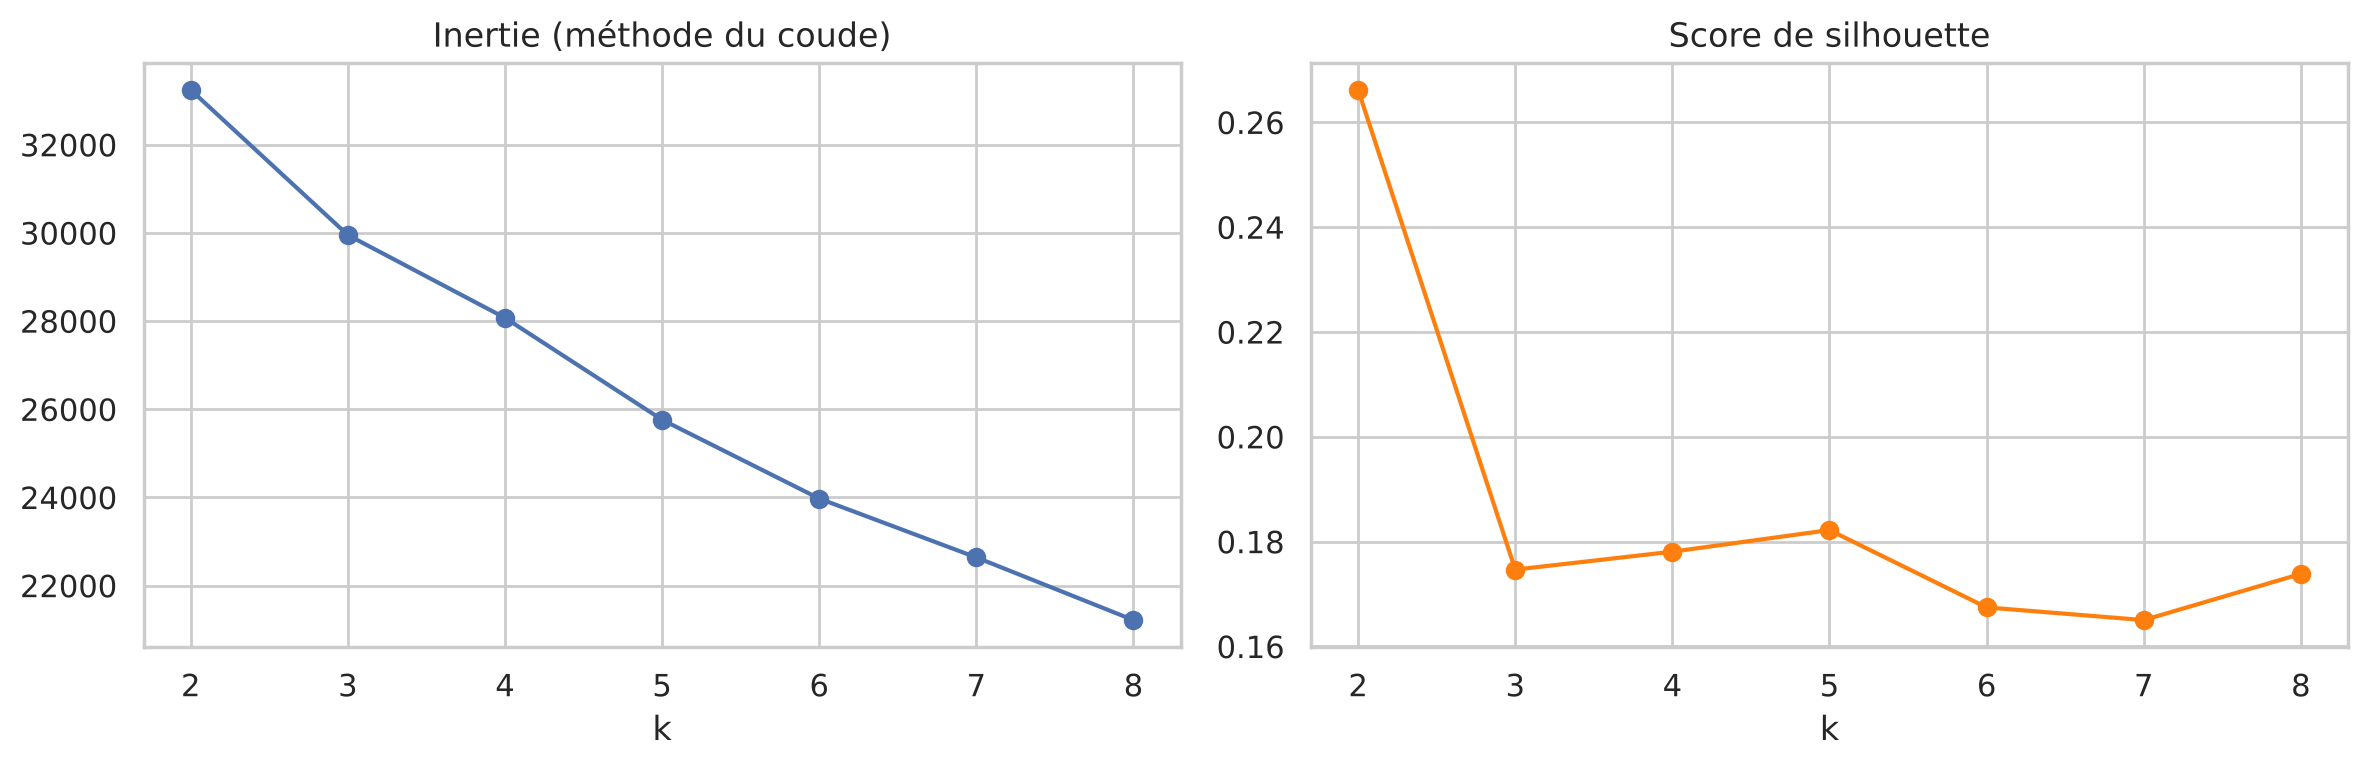

In [21]:
# Choix du nombre de groupes k : méthode du coude (inertie) et score de silhouette
ks = range(2, 9)
inerties, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_std)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X_std, km.labels_, sample_size=2000, random_state=SEED))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inerties, marker="o"); axes[0].set_title("Inertie (méthode du coude)"); axes[0].set_xlabel("k")
axes[1].plot(ks, silhouettes, marker="o", color="tab:orange"); axes[1].set_title("Score de silhouette"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()

In [22]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X_std)
df["cluster"] = km.labels_

profil = X_brut.assign(cluster=df["cluster"]).groupby("cluster")[
    ["montant_T_usd", "nb_investisseurs_T", "nb_fonds_T", "exp_max_investisseurs", "investisseurs_connus_T",
     "age_a_T_mois", "tours_etat_12m", "annee_T"]].mean()
profil["taille"] = df["cluster"].value_counts().sort_index()
profil["taux_y"] = df.groupby("cluster")[CIBLE].mean()
profil.round(2)

,montant_T_usd,nb_investisseurs_T,nb_fonds_T,exp_max_investisseurs,investisseurs_connus_T,age_a_T_mois,tours_etat_12m,annee_T,taille,taux_y
cluster,,,,,,,,,,
0,376527.82,0.00,0.00,0.00,0.0,9.39,503.61,2009.10,1067,0.14
1,760944.18,6.38,2.41,57.27,1.0,11.31,960.80,2009.70,232,0.55
2,335918.70,1.47,0.40,1.00,1.0,9.05,529.62,2009.01,770,0.24
3,322647.47,1.35,0.77,42.94,1.0,10.82,640.91,2009.40,434,0.39


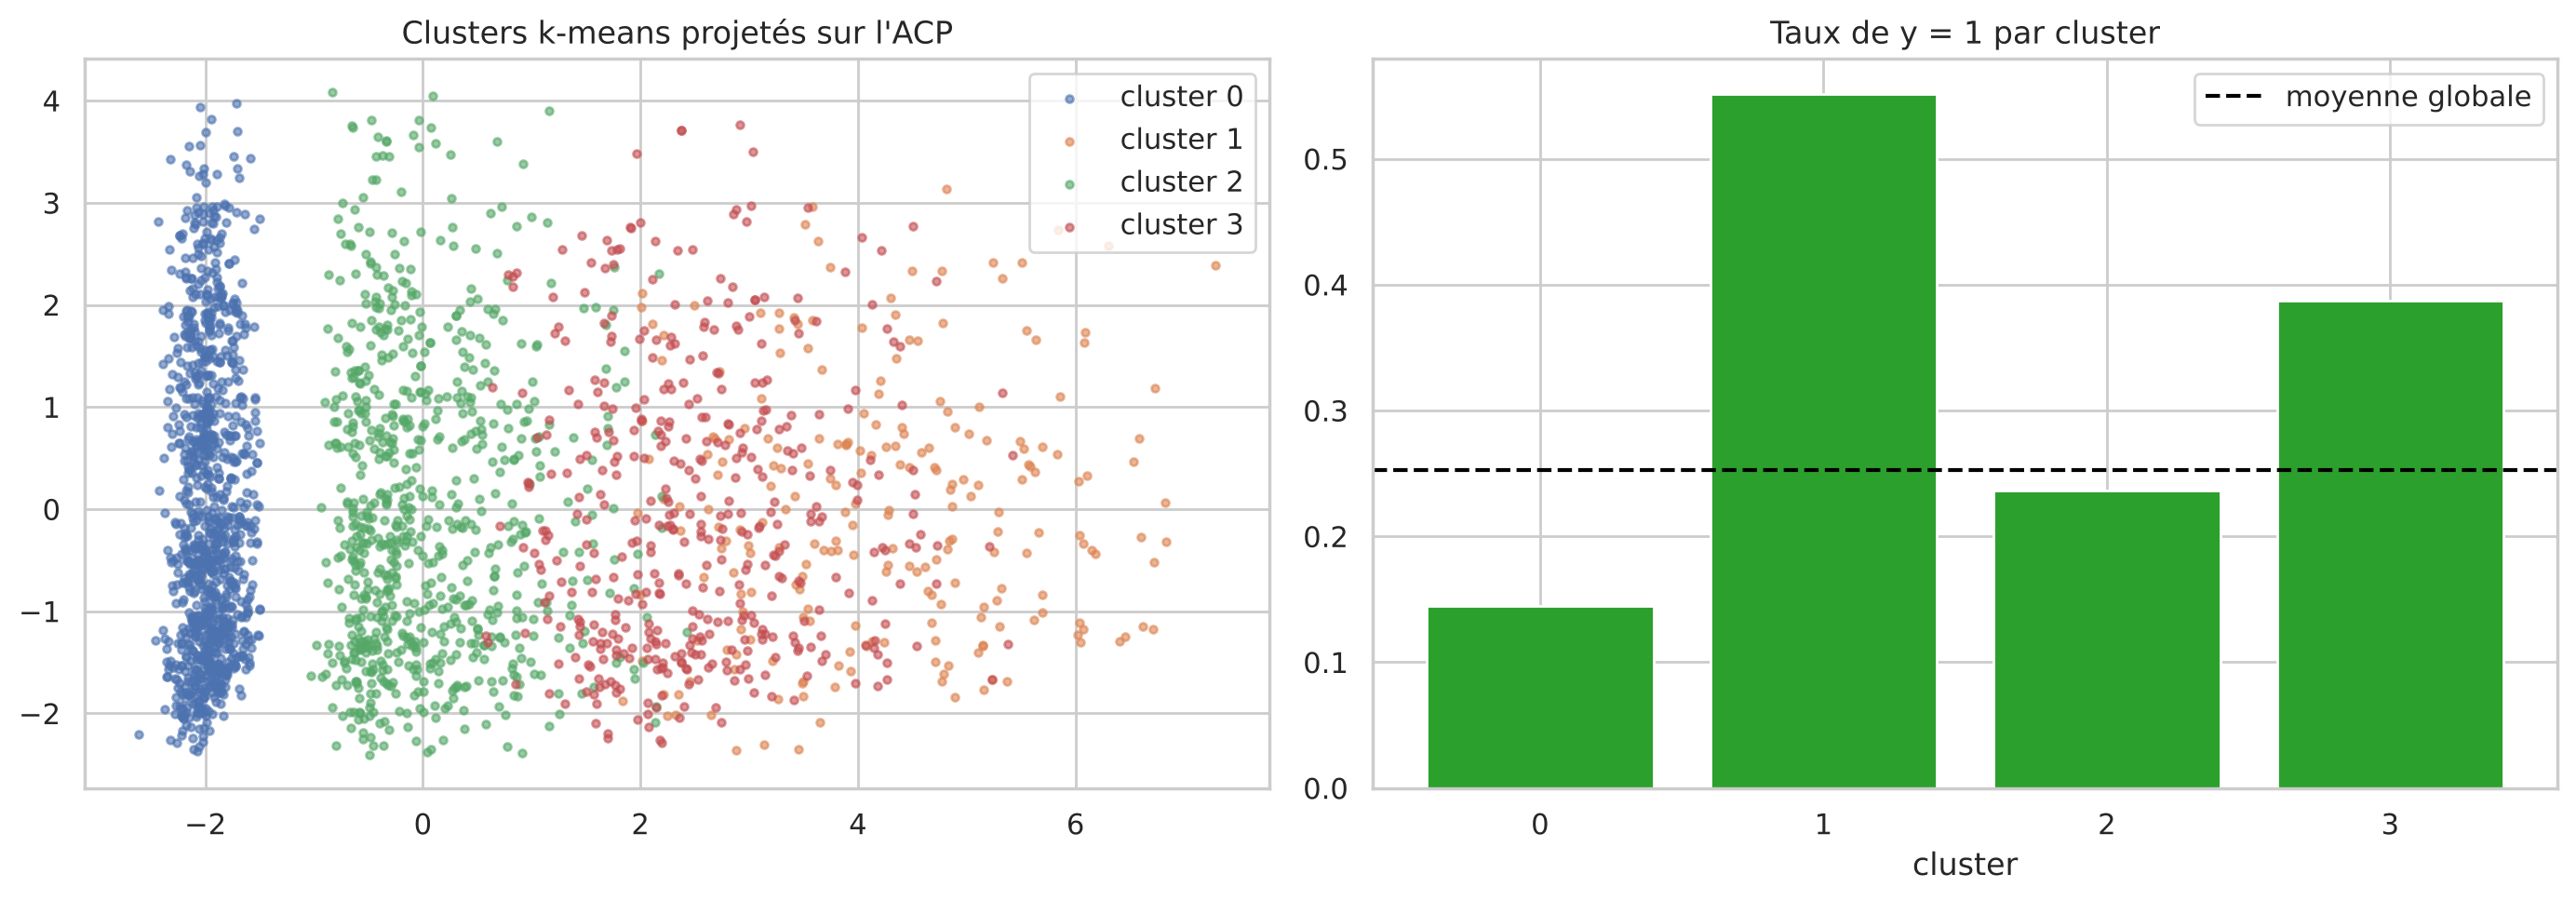

V de Cramér entre cluster et cible : 0.296


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for c in range(K):
    m = df["cluster"] == c
    axes[0].scatter(proj[m, 0], proj[m, 1], s=8, alpha=0.6, label=f"cluster {c}")
axes[0].legend(); axes[0].set_title("Clusters k-means projetés sur l'ACP")
axes[1].bar(profil.index.astype(str), profil["taux_y"], color="tab:green")
axes[1].axhline(df[CIBLE].mean(), color="black", ls="--", label="moyenne globale"); axes[1].legend()
axes[1].set_title("Taux de y = 1 par cluster"); axes[1].set_xlabel("cluster")
plt.tight_layout(); plt.show()
print("V de Cramér entre cluster et cible :", round(v_cramer(df["cluster"], df[CIBLE]), 3))

**Interprétation du clustering.** Le score de silhouette est faible (0,17 à 0,27) : les startups ne forment pas des groupes très nets. Le meilleur score est à k = 2, mais ce découpage sépare seulement « investisseurs connus / inconnus », ce que l'on sait déjà. On retient **k = 4** (silhouette proche de k = 3 et k = 5), qui donne des groupes interprétables :
- **cluster 0** : investisseurs du tour T inconnus (≈ 1 070 startups, **14 %** de succès) ;
- **cluster 2** : 1 à 2 investisseurs connus mais peu expérimentés, ≈ 340 k$ levés (≈ 770 startups, **24 %**) ;
- **cluster 3** : même montant (≈ 320 k$) mais investisseurs très expérimentés (≈ 430 startups, **39 %**) ;
- **cluster 1** : gros tours (≈ 760 k$) avec ~6 investisseurs dont 2 à 3 fonds, très expérimentés (≈ 230 startups, **55 %**).

Le **taux de succès varie de 14 % à 55 % d'un cluster à l'autre**, sans que la cible ait été utilisée pour les former (V de Cramér cluster / cible ≈ 0,30). La structure « naturelle » des données est donc fortement liée à la cible, et elle est surtout portée par les investisseurs. Piste : ajouter le numéro de cluster (ou la distance aux centres) comme variable supplémentaire et vérifier si cela aide les modèles.

## 7. Interprétations, hypothèses et conclusions

**Ce que l'on retient.**
1. Le jeu final compte **2 503 startups, 19 variables, 25 % de « oui »**. C'est un jeu petit et déséquilibré : validation croisée imbriquée, métriques ROC-AUC / PR-AUC / F1 et modèles régularisés.
2. Les **valeurs manquantes sont informatives** (investisseurs non renseignés = startups moins suivies) : imputation simple + **indicateurs de manque**, plutôt que suppression.
3. **Transformation log** des montants et comptages, **standardisation** pour les modèles linéaires, **regroupement des modalités rares**, retrait de `region`, âges négatifs ramenés à 0.
4. Les signaux les plus forts concernent **la qualité et le nombre des premiers investisseurs** et le **montant de la première levée** ; le secteur, l'État et le contexte de marché apportent un complément.
5. **Effet cohorte** marqué (crise de 2008) : test final sur la cohorte 2011, entraînement sur 2005–2010.

**Hypothèses à vérifier avec les modèles.**
- H1 : l'expérience des investisseurs du tour T est la variable la plus prédictive.
- H2 : les modèles non linéaires d'ensemble (forêts aléatoires, gradient boosting) battent nettement la régression logistique régularisée, car les effets sont non linéaires (seuils sur les comptages) et en interaction.
- H3 : rééquilibrer les classes améliore le rappel des « oui » sans trop dégrader la précision.

**Limites.** Données uniquement américaines et arrêtées en 2013 ; renseignement incomplet de Crunchbase (biais vers les startups médiatisées) ; pas d'information sur les fondateurs dans cet export.

**Suite (notebook 3).** Pipelines scikit-learn (imputation, log, encodage, standardisation), régression logistique L1/L2 (et version polynomiale), forêt aléatoire, gradient boosting (XGBoost / LightGBM), stacking, validation croisée imbriquée avec le même nombre de plis pour tous les modèles, courbes d'apprentissage et comparaison sur le jeu de test 2011.